In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import BayesianRidge

# Regression Metrics & Models
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression, HuberRegressor, RidgeCV, ElasticNetCV
from pysr import PySRRegressor

# Classification Metrics & Models
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, confusion_matrix
from sklearn.linear_model import LogisticRegressionCV, RidgeClassifierCV

RANDOM_STATE = 42


# ==========================================
# 1. Data Loading and Splitting
# ==========================================
def load_and_prep_data(filepath):
    df = pd.read_csv(filepath)

    features = [
        "nHM",
        "piPC09",
        "PCD",
        "X2Av",
        "MLOGP",
        "ON1V",
        "N-072",
        "B02[C-N]",
        "F04[C-O]",
    ]
    X = df[features]
    y_reg = df["regression_target"]

    # Encode classification targets to 0, 1, 2...
    encoder = LabelEncoder()
    y_class = encoder.fit_transform(df["classification_target"])

    # Stratify by classification target to ensure balanced train/test sets
    X_train, X_test, y_reg_train, y_reg_test, y_class_train, y_class_test = (
        train_test_split(
            X,
            y_reg,
            y_class,
            test_size=0.2,
            random_state=RANDOM_STATE,
            stratify=y_class,
        )
    )

    return X_train, X_test, y_reg_train, y_reg_test, y_class_train, y_class_test


# ==========================================
# 2. Preprocessing
# ==========================================
continuous_cols = ["nHM", "piPC09", "PCD", "X2Av", "MLOGP", "ON1V"]
fragment_cols = ["N-072", "B02[C-N]", "F04[C-O]"]

preprocessor = ColumnTransformer(
    [
        (
            "mice_cont",
            Pipeline(
                [
                    (
                        "imputer",
                        IterativeImputer(
                            estimator=BayesianRidge(),
                            max_iter=15,
                            random_state=RANDOM_STATE,
                        ),
                    ),
                    ("scaler", RobustScaler()),
                ]
            ),
            continuous_cols,
        ),
        (
            "zero_frag",
            Pipeline(
                [
                    ("imputer", SimpleImputer(strategy="constant", fill_value=0.0)),
                    ("scaler", RobustScaler()),
                ]
            ),
            fragment_cols,
        ),
    ],
    remainder="drop",
)
from sklearn.cross_decomposition import PLSRegression
from sklearn.preprocessing import KBinsDiscretizer
from sklearn.compose import TransformedTargetRegressor

# ==========================================
# Breakthrough 1: Feature Discretization Pipeline
# ==========================================
# This turns continuous chemical properties into "steps", allowing linear models
# to capture non-linear drop-offs (like the Lipinski Rule of 5 cliff) safely.
binned_preprocessor = ColumnTransformer(
    [
        (
            "binned_cont",
            Pipeline(
                [
                    (
                        "imputer",
                        IterativeImputer(
                            estimator=BayesianRidge(), max_iter=15, random_state=42
                        ),
                    ),
                    # strategy='quantile' ensures each bin gets an equal number of molecules
                    (
                        "binner",
                        KBinsDiscretizer(
                            n_bins=5, encode="onehot-dense", strategy="quantile"
                        ),
                    ),
                ]
            ),
            continuous_cols,
        ),
        (
            "zero_frag",
            Pipeline(
                [
                    ("imputer", SimpleImputer(strategy="constant", fill_value=0.0)),
                    ("scaler", RobustScaler()),
                ]
            ),
            fragment_cols,
        ),
    ],
    remainder="drop",
)


# ==========================================
# Breakthrough 2 & 3: PLS and Target Transformation
# ==========================================
def get_breakthrough_models():
    return {
        # Standard PLS (must be tuned, usually 2 to 5 components is best for 9 features)
        "PLS Regression (3 Components)": PLSRegression(n_components=3),
        # PLS on Binned Features (Handles non-linearities)
        "Binned PLS": Pipeline(
            [("binner", binned_preprocessor), ("pls", PLSRegression(n_components=5))]
        ),
        # Log-Transformed Ridge
        # Trains on log1p(y) to prevent massive outliers from destroying the test score,
        # then automatically applies expm1() to predictions.
        "Log-Transformed Ridge": TransformedTargetRegressor(
            regressor=RidgeCV(alphas=np.logspace(-3, 3, 100), cv=5),
            func=np.log1p,
            inverse_func=np.expm1,
        ),
        # Binned Ridge (The linear equivalent of a Random Forest)
        "Binned Ridge": Pipeline(
            [
                ("binner", binned_preprocessor),
                ("model", RidgeCV(alphas=np.logspace(-3, 3, 100), cv=5)),
            ]
        ),
    }


# Run these by replacing `get_regression_models()` in your pipeline with `get_breakthrough_models()`


# ==========================================
# 3. Model Definitions
# ==========================================
def get_regression_models():
    return {
        "OLS Linear": LinearRegression(),
        "Robust Linear (Huber)": HuberRegressor(max_iter=2000, epsilon=1.35),
        "Ridge Regressor (L2)": RidgeCV(alphas=np.logspace(-3, 3, 100), cv=5),
        "ElasticNet (L1+L2)": ElasticNetCV(
            l1_ratio=[0.1, 0.5, 0.9, 0.95], cv=5, max_iter=5000
        ),
        "PySR Symbolic": PySRRegressor(
            niterations=100,
            populations=30,
            population_size=30,
            binary_operators=["+", "-", "*", "/"],
            unary_operators=["square", "cube", "cos", "exp", "sin", "sqrt"],
            maxsize=15,
            random_state=RANDOM_STATE,
            verbosity=0,
        ),
    }


def get_classification_models():
    return {
        # CV versions automatically tune regularization to prevent the overfitting you just saw
        "Logistic Regression (CV)": LogisticRegressionCV(
            Cs=20,
            cv=5,
            class_weight="balanced",
            max_iter=2000,
            random_state=RANDOM_STATE,
        ),
        "Ridge Classifier (CV)": RidgeClassifierCV(
            alphas=np.logspace(-3, 3, 100), cv=5, class_weight="balanced"
        ),
    }


# ==========================================
# 4. Evaluation Metrics
# ==========================================
def evaluate_regression(name, y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = root_mean_squared_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    pearson_r, _ = pearsonr(y_true, y_pred)

    print(f"--- {name} ---")
    print(f"MAE:        {mae:.4f}")
    print(f"RMSE:       {rmse:.4f}")
    print(f"R2:         {r2:.4f}")
    print(f"Pearson r2: {pearson_r**2:.4f}\n")
    return {
        "Task": "Regression",
        "Model": name,
        "Metric_1 (R2)": r2,
        "Metric_2 (RMSE)": rmse,
    }


def evaluate_classification(name, y_true, y_pred, y_prob=None):
    acc = accuracy_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred, average="weighted")

    print(f"--- {name} ---")
    print(f"Accuracy:   {acc:.4f}")
    print(f"F1 Score:   {f1:.4f}\n")
    return {
        "Task": "Classification",
        "Model": name,
        "Metric_1 (Acc)": acc,
        "Metric_2 (F1)": f1,
    }


# ==========================================
# 5. Main Execution Pipeline
# ==========================================
def run_pipeline(filepath="your_dataset.csv"):
    X_train, X_test, y_reg_train, y_reg_test, y_class_train, y_class_test = (
        load_and_prep_data(filepath)
    )

    # Apply imputation and scaling safely without leaking test data
    X_train_processed = preprocessor.fit_transform(X_train)
    X_test_processed = preprocessor.transform(X_test)

    results = []
    reg_predictions = {}

    print("==========================================")
    print("         CLASSIFICATION BENCHMARK         ")
    print("==========================================\n")

    class_models = get_classification_models()
    for name, model in class_models.items():
        model.fit(X_train_processed, y_class_train)
        preds = model.predict(X_test_processed)
        results.append(evaluate_classification(name, y_class_test, preds))

    print("==========================================")
    print("           REGRESSION BENCHMARK           ")
    print("==========================================\n")

    reg_models = get_breakthrough_models()
    for name, model in reg_models.items():
        model.fit(X_train_processed, y_reg_train)
        preds = model.predict(X_test_processed)
        reg_predictions[name] = preds
        results.append(evaluate_regression(name, y_reg_test, preds))

        if name == "PySR Symbolic":
            print("Best Equation Discovered by PySR:")
            print(model.sympy(), "\n")

    # ==========================================
    # 6. Visualization (Regression Only)
    # ==========================================
    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    axes = axes.flatten()

    for i, (name, preds) in enumerate(reg_predictions.items()):
        if i >= len(axes):
            break
        ax = axes[i]
        sns.scatterplot(x=y_reg_test, y=preds, alpha=0.6, ax=ax)

        # Perfect prediction diagonal line
        min_val = min(y_reg_test.min(), preds.min())
        max_val = max(y_reg_test.max(), preds.max())
        ax.plot([min_val, max_val], [min_val, max_val], "r--", lw=2)

        ax.set_title(f"{name}\nR2: {r2_score(y_reg_test, preds):.3f}")
        ax.set_xlabel("Observed Target")
        ax.set_ylabel("Predicted Target")
        ax.grid(True, linestyle="--", alpha=0.7)

    plt.tight_layout()
    plt.show()

    return pd.DataFrame(results)


# Execute the script
# df_results = run_pipeline("your_dataset.csv")

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr

# Scikit-Learn tools
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler, LabelEncoder, KBinsDiscretizer
from sklearn.impute import SimpleImputer
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.linear_model import BayesianRidge

# Regression Metrics & Models
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression, HuberRegressor, RidgeCV, ElasticNetCV
from sklearn.cross_decomposition import PLSRegression
from pysr import PySRRegressor

# Classification Metrics & Models
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
from sklearn.linear_model import LogisticRegressionCV, RidgeClassifierCV

RANDOM_STATE = 42


# ==========================================
# 1. Data Loading and Splitting
# ==========================================
def load_and_prep_data(filepath):
    df = pd.read_csv(filepath)

    features = [
        "nHM",
        "piPC09",
        "PCD",
        "X2Av",
        "MLOGP",
        "ON1V",
        "N-072",
        "B02[C-N]",
        "F04[C-O]",
    ]
    X = df[features]
    y_reg = df["regression_target"]

    # Encode classification targets starting from 0
    encoder = LabelEncoder()
    y_class = encoder.fit_transform(df["classification_target"])

    # Stratify by classification target to ensure perfectly balanced sets
    X_train, X_test, y_reg_train, y_reg_test, y_class_train, y_class_test = (
        train_test_split(
            X,
            y_reg,
            y_class,
            test_size=0.2,
            random_state=RANDOM_STATE,
            stratify=y_class,
        )
    )

    return X_train, X_test, y_reg_train, y_reg_test, y_class_train, y_class_test


# ==========================================
# 2. Preprocessors
# ==========================================
continuous_cols = ["nHM", "piPC09", "PCD", "X2Av", "MLOGP", "ON1V"]
fragment_cols = ["N-072", "B02[C-N]", "F04[C-O]"]

# Standard MICE Preprocessor
standard_preprocessor = ColumnTransformer(
    [
        (
            "mice_cont",
            Pipeline(
                [
                    (
                        "imputer",
                        IterativeImputer(
                            estimator=BayesianRidge(),
                            max_iter=15,
                            random_state=RANDOM_STATE,
                        ),
                    ),
                    ("scaler", RobustScaler()),
                ]
            ),
            continuous_cols,
        ),
        (
            "zero_frag",
            Pipeline(
                [
                    ("imputer", SimpleImputer(strategy="constant", fill_value=0.0)),
                    ("scaler", RobustScaler()),
                ]
            ),
            fragment_cols,
        ),
    ],
    remainder="drop",
)

# Discretizing Preprocessor for capturing Non-Linearities safely
binned_preprocessor = ColumnTransformer(
    [
        (
            "binned_cont",
            Pipeline(
                [
                    (
                        "imputer",
                        IterativeImputer(
                            estimator=BayesianRidge(),
                            max_iter=15,
                            random_state=RANDOM_STATE,
                        ),
                    ),
                    (
                        "binner",
                        KBinsDiscretizer(
                            n_bins=5, encode="onehot-dense", strategy="quantile"
                        ),
                    ),
                ]
            ),
            continuous_cols,
        ),
        (
            "zero_frag",
            Pipeline(
                [
                    ("imputer", SimpleImputer(strategy="constant", fill_value=0.0)),
                    ("scaler", RobustScaler()),
                ]
            ),
            fragment_cols,
        ),
    ],
    remainder="drop",
)


# ==========================================
# 3. Model Definitions (Wrapped in Pipelines)
# ==========================================
def get_classification_models():
    return {
        "Logistic Regression (CV)": Pipeline(
            [
                ("prep", standard_preprocessor),
                (
                    "model",
                    LogisticRegressionCV(
                        Cs=20,
                        cv=5,
                        class_weight="balanced",
                        max_iter=2000,
                        random_state=RANDOM_STATE,
                    ),
                ),
            ]
        ),
        "Ridge Classifier (CV)": Pipeline(
            [
                ("prep", standard_preprocessor),
                (
                    "model",
                    RidgeClassifierCV(
                        alphas=np.logspace(-3, 3, 100), cv=5, class_weight="balanced"
                    ),
                ),
            ]
        ),
    }


def get_regression_models():
    return {
        "Robust Linear (Huber)": Pipeline(
            [
                ("prep", standard_preprocessor),
                ("model", HuberRegressor(max_iter=2000, epsilon=1.35)),
            ]
        ),
        "PLS Regression (3 Comp)": Pipeline(
            [("prep", standard_preprocessor), ("model", PLSRegression(n_components=3))]
        ),
        "Binned PLS": Pipeline(
            [("prep", binned_preprocessor), ("model", PLSRegression(n_components=5))]
        ),
        "Binned Ridge": Pipeline(
            [
                ("prep", binned_preprocessor),
                ("model", RidgeCV(alphas=np.logspace(-3, 3, 100), cv=5)),
            ]
        ),
        "PySR Symbolic Regression": Pipeline(
            [
                ("prep", standard_preprocessor),
                (
                    "model",
                    PySRRegressor(
                        niterations=100,
                        populations=30,
                        population_size=30,
                        binary_operators=["+", "-", "*", "/"],
                        unary_operators=["square", "cube", "cos", "exp", "sin", "sqrt"],
                        maxsize=15,
                        random_state=RANDOM_STATE,
                        verbosity=0,
                    ),
                ),
            ]
        ),
    }


# ==========================================
# 4. Evaluation Metrics
# ==========================================
def evaluate_regression(name, y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = root_mean_squared_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    pearson_r, _ = pearsonr(y_true, y_pred)

    print(f"--- {name} ---")
    print(f"MAE:        {mae:.4f}")
    print(f"RMSE:       {rmse:.4f}")
    print(f"R2:         {r2:.4f}")
    print(f"Pearson r2: {pearson_r**2:.4f}\n")
    return {"Task": "Regression", "Model": name, "R2": r2, "RMSE": rmse}


def evaluate_classification(name, y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred, average="weighted")

    print(f"--- {name} ---")
    print(f"Accuracy:   {acc:.4f}")
    print(f"F1 Score:   {f1:.4f}\n")
    return {"Task": "Classification", "Model": name, "Accuracy": acc, "F1": f1}


# ==========================================
# 5. Main Execution Pipeline
# ==========================================
def run_pipeline(filepath="your_dataset.csv"):
    X_train, X_test, y_reg_train, y_reg_test, y_class_train, y_class_test = (
        load_and_prep_data(filepath)
    )

    results = []
    reg_predictions = {}

    print("==========================================")
    print("         CLASSIFICATION BENCHMARK         ")
    print("==========================================\n")

    class_models = get_classification_models()
    for name, model in class_models.items():
        print(f"Training {name}...")
        model.fit(X_train, y_class_train)
        preds = model.predict(X_test)
        results.append(evaluate_classification(name, y_class_test, preds))

    print("==========================================")
    print("           REGRESSION BENCHMARK           ")
    print("==========================================\n")

    reg_models = get_regression_models()
    for name, model in reg_models.items():
        print(f"Training {name}...")

        # PySR throws warnings if it receives DataFrames directly inside a pipeline sometimes,
        # so we rely on the pipeline to handle numpy arrays seamlessly.
        model.fit(X_train, y_reg_train)
        preds = model.predict(X_test)

        reg_predictions[name] = preds
        results.append(evaluate_regression(name, y_reg_test, preds))

        if "PySR" in name:
            print("Best Equation Discovered by PySR:")
            print(model.named_steps["model"].sympy(), "\n")

    # ==========================================
    # 6. Visualization (Regression Only)
    # ==========================================
    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    axes = axes.flatten()

    for i, (name, preds) in enumerate(reg_predictions.items()):
        if i >= len(axes):
            break
        ax = axes[i]
        sns.scatterplot(x=y_reg_test, y=preds, alpha=0.6, ax=ax)

        min_val = min(y_reg_test.min(), preds.min())
        max_val = max(y_reg_test.max(), preds.max())
        ax.plot([min_val, max_val], [min_val, max_val], "r--", lw=2)

        ax.set_title(f"{name}\nR2: {r2_score(y_reg_test, preds):.3f}")
        ax.set_xlabel("Observed Target")
        ax.set_ylabel("Predicted Target")
        ax.grid(True, linestyle="--", alpha=0.7)

    plt.tight_layout()
    plt.show()

    return pd.DataFrame(results)


# ==========================================
# Execution Trigger
# ==========================================
# df_results = run_pipeline("your_dataset.csv")
# display(df_results.sort_values(by=["Task", "R2", "Accuracy"], ascending=False))

         CLASSIFICATION BENCHMARK         

Training Logistic Regression (CV)...
--- Logistic Regression (CV) ---
Accuracy:   0.5840
F1 Score:   0.6307

Training Ridge Classifier (CV)...


/Users/otsep/Desktop/Personal/KSE/ml/personal/KSE_ML_for_bioinformatics/.venv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:2092: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
/Users/otsep/Desktop/Personal/KSE/ml/personal/KSE_ML_for_bioinformatics/.venv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:2137: FutureWarning: The default value of the parameter 'scoring' will change from None, i.e. accuracy, to 'neg_log_loss' in version 1.11. To silence this warning, explicitly set the scoring parameter: scoring='neg_log_loss' for the new, scoring='accuracy' or scoring=None for the old default.
  warnings.warn(
/Users/otsep/Desktop/Personal/KSE/ml/personal/KSE_ML_for_bioinformatics/.venv/lib/python3.11/site-packages/sklearn

--- Ridge Classifier (CV) ---
Accuracy:   0.5840
F1 Score:   0.6314

           REGRESSION BENCHMARK           

Training Robust Linear (Huber)...
--- Robust Linear (Huber) ---
MAE:        0.5931
RMSE:       0.8330
R2:         0.5366
Pearson r2: 0.5866

Training PLS Regression (3 Comp)...
--- PLS Regression (3 Comp) ---
MAE:        0.6035
RMSE:       0.8220
R2:         0.5487
Pearson r2: 0.5747

Training Binned PLS...
--- Binned PLS ---
MAE:        0.6152
RMSE:       0.7828
R2:         0.5907
Pearson r2: 0.5997

Training Binned Ridge...
--- Binned Ridge ---
MAE:        0.6029
RMSE:       0.7750
R2:         0.5989
Pearson r2: 0.6038

Training PySR Symbolic Regression...


/Users/otsep/Desktop/Personal/KSE/ml/personal/KSE_ML_for_bioinformatics/.venv/lib/python3.11/site-packages/pysr/sr.py:2405: UserWarning: Note: Setting `random_state` without also setting `deterministic=True` and `parallelism='serial'` will result in non-deterministic searches.
  warnings.warn(


--- PySR Symbolic Regression ---
MAE:        0.6311
RMSE:       0.7929
R2:         0.5800
Pearson r2: 0.6085

Best Equation Discovered by PySR:
x4 + 1.9834657 



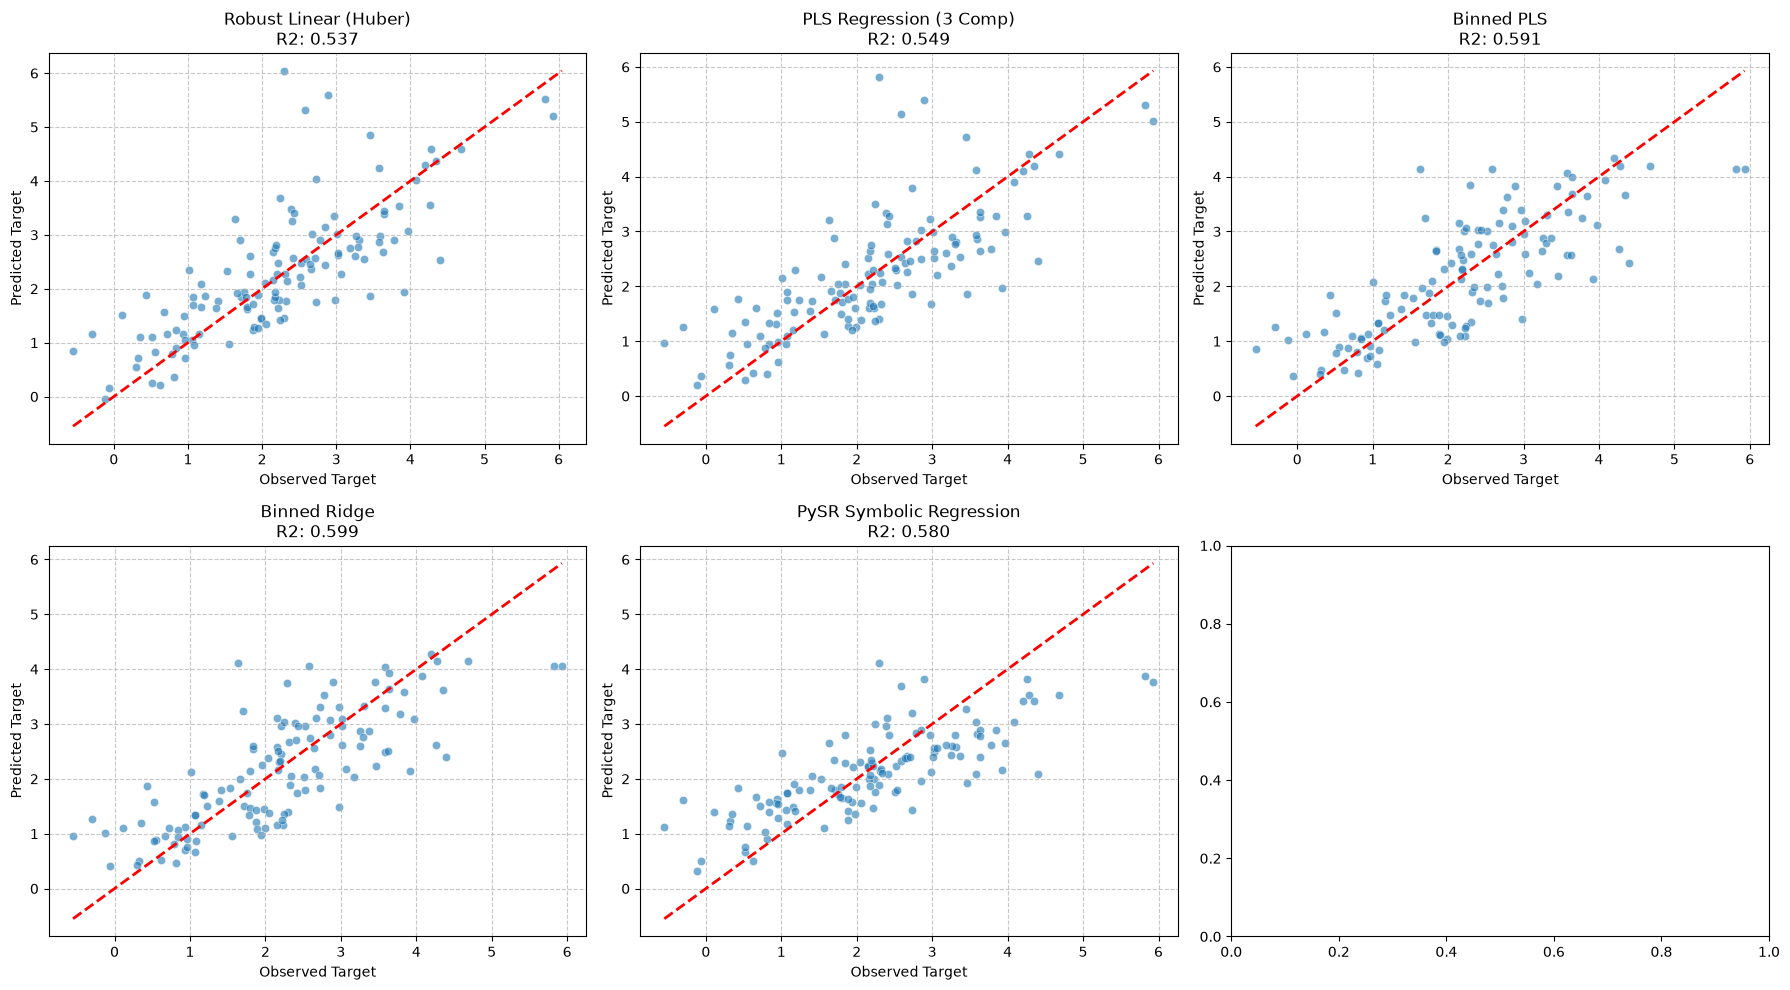

In [28]:
df_results = run_pipeline("QSAR_challenge_train_80pct.csv")

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import RobustScaler, LabelEncoder, KBinsDiscretizer
from sklearn.impute import SimpleImputer
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import BayesianRidge

# Models
from sklearn.linear_model import LinearRegression, HuberRegressor, Ridge, ElasticNet
from sklearn.linear_model import LogisticRegression, RidgeClassifier
from sklearn.cross_decomposition import PLSRegression
from sklearn.metrics import (
    mean_absolute_error,
    root_mean_squared_error,
    r2_score,
    accuracy_score,
    f1_score,
)
from pygam import LinearGAM, LogisticGAM, s
from pysr import PySRRegressor

RANDOM_STATE = 42


# ==========================================
# 1. Data Loading
# ==========================================
def load_and_prep_data(filepath):
    df = pd.read_csv(filepath)
    features = [
        "nHM",
        "piPC09",
        "PCD",
        "X2Av",
        "MLOGP",
        "ON1V",
        "N-072",
        "B02[C-N]",
        "F04[C-O]",
    ]

    X = df[features]
    y_reg = df["regression_target"]

    encoder = LabelEncoder()
    y_class = encoder.fit_transform(df["classification_target"])

    X_train, X_test, y_reg_train, y_reg_test, y_class_train, y_class_test = (
        train_test_split(
            X,
            y_reg,
            y_class,
            test_size=0.2,
            random_state=RANDOM_STATE,
            stratify=y_class,
        )
    )
    return X_train, X_test, y_reg_train, y_reg_test, y_class_train, y_class_test


# ==========================================
# 2. Preprocessors
# ==========================================
continuous_cols = ["nHM", "piPC09", "PCD", "X2Av", "MLOGP", "ON1V"]
fragment_cols = ["N-072", "B02[C-N]", "F04[C-O]"]

standard_prep = ColumnTransformer(
    [
        (
            "mice_cont",
            Pipeline(
                [
                    (
                        "imputer",
                        IterativeImputer(
                            estimator=BayesianRidge(),
                            max_iter=15,
                            random_state=RANDOM_STATE,
                        ),
                    ),
                    ("scaler", RobustScaler()),
                ]
            ),
            continuous_cols,
        ),
        (
            "zero_frag",
            Pipeline(
                [
                    ("imputer", SimpleImputer(strategy="constant", fill_value=0.0)),
                    ("scaler", RobustScaler()),
                ]
            ),
            fragment_cols,
        ),
    ],
    remainder="drop",
)

binned_prep = ColumnTransformer(
    [
        (
            "binned_cont",
            Pipeline(
                [
                    (
                        "imputer",
                        IterativeImputer(
                            estimator=BayesianRidge(),
                            max_iter=15,
                            random_state=RANDOM_STATE,
                        ),
                    ),
                    (
                        "binner",
                        KBinsDiscretizer(encode="onehot-dense", strategy="quantile"),
                    ),  # n_bins tuned by GridSearchCV
                ]
            ),
            continuous_cols,
        ),
        (
            "zero_frag",
            Pipeline(
                [
                    ("imputer", SimpleImputer(strategy="constant", fill_value=0.0)),
                    ("scaler", RobustScaler()),
                ]
            ),
            fragment_cols,
        ),
    ],
    remainder="drop",
)

# ==========================================
# 3. GridSearchCV Dictionaries
# ==========================================
classification_grids = {
    "Logistic Regression": {
        "pipeline": Pipeline(
            [
                ("prep", standard_prep),
                (
                    "model",
                    LogisticRegression(
                        class_weight="balanced",
                        max_iter=2000,
                        random_state=RANDOM_STATE,
                    ),
                ),
            ]
        ),
        "params": {
            "model__C": [0.001, 0.01, 0.1, 1, 10, 100],
            "model__penalty": ["l2"],
        },
    },
    "Ridge Classifier": {
        "pipeline": Pipeline(
            [
                ("prep", standard_prep),
                ("model", RidgeClassifier(class_weight="balanced")),
            ]
        ),
        "params": {"model__alpha": np.logspace(-3, 3, 20)},
    },
}

regression_grids = {
    "OLS Linear": {
        "pipeline": Pipeline([("prep", standard_prep), ("model", LinearRegression())]),
        "params": {},  # OLS has no hyperparameters to tune
    },
    "Robust Linear (Huber)": {
        "pipeline": Pipeline(
            [("prep", standard_prep), ("model", HuberRegressor(max_iter=2000))]
        ),
        "params": {
            "model__epsilon": [1.1, 1.2, 1.35, 1.5, 1.75],
            "model__alpha": [0.0001, 0.001, 0.01, 0.1, 1.0],
        },
    },
    "Ridge Regressor": {
        "pipeline": Pipeline([("prep", standard_prep), ("model", Ridge())]),
        "params": {"model__alpha": np.logspace(-3, 3, 50)},
    },
    "ElasticNet": {
        "pipeline": Pipeline(
            [("prep", standard_prep), ("model", ElasticNet(max_iter=5000))]
        ),
        "params": {
            "model__alpha": np.logspace(-3, 1, 20),
            "model__l1_ratio": [0.1, 0.3, 0.5, 0.7, 0.9, 0.99],
        },
    },
    "PLS Regression": {
        "pipeline": Pipeline([("prep", standard_prep), ("model", PLSRegression())]),
        "params": {"model__n_components": [2, 3, 4, 5, 6, 7, 8]},
    },
    "Binned Ridge": {
        "pipeline": Pipeline([("prep", binned_prep), ("model", Ridge())]),
        "params": {
            "prep__binned_cont__binner__n_bins": [3, 4, 5, 6, 7],
            "model__alpha": np.logspace(-2, 3, 20),
        },
    },
    "Binned PLS": {
        "pipeline": Pipeline([("prep", binned_prep), ("model", PLSRegression())]),
        "params": {
            "prep__binned_cont__binner__n_bins": [3, 4, 5, 6],
            "model__n_components": [2, 3, 4, 5, 6, 8, 10],
        },
    },
}


# ==========================================
# 4. Execution Pipeline
# ==========================================
def run_grid_searches(filepath="your_dataset.csv"):
    X_train, X_test, y_reg_train, y_reg_test, y_class_train, y_class_test = (
        load_and_prep_data(filepath)
    )

    print("==========================================")
    print("        CLASSIFICATION GRID SEARCH        ")
    print("==========================================\n")

    for name, config in classification_grids.items():
        print(f"Tuning {name}...")
        grid = GridSearchCV(
            config["pipeline"], config["params"], cv=5, scoring="f1_macro", n_jobs=-1
        )
        grid.fit(X_train, y_class_train)

        preds = grid.predict(X_test)
        print(f"Best Params: {grid.best_params_}")
        print(
            f"Test Accuracy: {accuracy_score(y_class_test, preds):.4f} | Test F1: {f1_score(y_class_test, preds, average='weighted'):.4f}\n"
        )

    # Native PyGAM Classification Search
    print("Tuning Logistic GAM (OVR)...")
    X_train_processed = standard_prep.fit_transform(X_train)
    X_test_processed = standard_prep.transform(X_test)
    unique_classes = np.unique(y_class_train)
    probs = np.zeros((X_test_processed.shape[0], len(unique_classes)))

    for idx, cls in enumerate(unique_classes):
        y_binary = (y_class_train == cls).astype(float)
        gam = LogisticGAM(s(0) + s(1) + s(2) + s(3) + s(4) + s(5) + s(6) + s(7) + s(8))
        gam.gridsearch(
            X_train_processed, y_binary, lam=np.logspace(-3, 3, 20), progress=False
        )
        probs[:, idx] = gam.predict_proba(X_test_processed)

    gam_preds = unique_classes[np.argmax(probs, axis=1)]
    print(f"Best Params: GAM independently optimized lambda per class")
    print(
        f"Test Accuracy: {accuracy_score(y_class_test, gam_preds):.4f} | Test F1: {f1_score(y_class_test, gam_preds, average='weighted'):.4f}\n"
    )

    print("==========================================")
    print("          REGRESSION GRID SEARCH          ")
    print("==========================================\n")

    for name, config in regression_grids.items():
        print(f"Tuning {name}...")
        grid = GridSearchCV(
            config["pipeline"],
            config["params"],
            cv=5,
            scoring="neg_root_mean_squared_error",
            n_jobs=-1,
        )
        grid.fit(X_train, y_reg_train)

        preds = grid.predict(X_test)
        print(f"Best Params: {grid.best_params_}")
        print(
            f"Test R2: {r2_score(y_reg_test, preds):.4f} | Test RMSE: {root_mean_squared_error(y_reg_test, preds):.4f}\n"
        )

    # Native PyGAM Regression Search
    print("Tuning Linear GAM...")
    reg_gam = LinearGAM(s(0) + s(1) + s(2) + s(3) + s(4) + s(5) + s(6) + s(7) + s(8))
    reg_gam.gridsearch(
        X_train_processed, y_reg_train, lam=np.logspace(-3, 3, 20), progress=False
    )
    gam_reg_preds = reg_gam.predict(X_test_processed)
    print(f"Best Params: Selected Lambda penalty via GAM GCV")
    print(
        f"Test R2: {r2_score(y_reg_test, gam_reg_preds):.4f} | Test RMSE: {root_mean_squared_error(y_reg_test, gam_reg_preds):.4f}\n"
    )

    # Native PySR Symbolic Search
    print("Running PySR Symbolic Regression...")
    pysr_model = PySRRegressor(
        niterations=200,
        populations=40,
        population_size=40,
        binary_operators=["+", "-", "*", "/"],
        unary_operators=["square", "cube", "cos", "exp", "sin", "sqrt"],
        maxsize=15,
        random_state=RANDOM_STATE,
        verbosity=0,
    )
    pysr_model.fit(X_train_processed, y_reg_train)
    pysr_preds = pysr_model.predict(X_test_processed)
    print(
        f"Test R2: {r2_score(y_reg_test, pysr_preds):.4f} | Test RMSE: {root_mean_squared_error(y_reg_test, pysr_preds):.4f}"
    )
    print(f"Best Formula: {pysr_model.sympy()}\n")


# Execute
# run_grid_searches("your_dataset.csv")

In [32]:
run_grid_searches("QSAR_challenge_train_80pct.csv")

        CLASSIFICATION GRID SEARCH        

Tuning Logistic Regression...


/Users/otsep/Desktop/Personal/KSE/ml/personal/KSE_ML_for_bioinformatics/.venv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/otsep/Desktop/Personal/KSE/ml/personal/KSE_ML_for_bioinformatics/.venv/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='

Best Params: {'model__C': 0.01, 'model__penalty': 'l2'}
Test Accuracy: 0.5840 | Test F1: 0.6300

Tuning Ridge Classifier...
Best Params: {'model__alpha': np.float64(233.57214690901213)}
Test Accuracy: 0.5760 | Test F1: 0.6228

Tuning Logistic GAM (OVR)...


/Users/otsep/Desktop/Personal/KSE/ml/personal/KSE_ML_for_bioinformatics/.venv/lib/python3.11/site-packages/pygam/links.py:137: RuntimeWarning: divide by zero encountered in divide
  return dist.levels / (mu * (dist.levels - mu))
/Users/otsep/Desktop/Personal/KSE/ml/personal/KSE_ML_for_bioinformatics/.venv/lib/python3.11/site-packages/pygam/pygam.py:631: RuntimeWarning: invalid value encountered in multiply
  self.link.gradient(mu, self.distribution) ** 2
/Users/otsep/Desktop/Personal/KSE/ml/personal/KSE_ML_for_bioinformatics/.venv/lib/python3.11/site-packages/pygam/links.py:137: RuntimeWarning: overflow encountered in divide
  return dist.levels / (mu * (dist.levels - mu))
/Users/otsep/Desktop/Personal/KSE/ml/personal/KSE_ML_for_bioinformatics/.venv/lib/python3.11/site-packages/pygam/pygam.py:631: RuntimeWarning: overflow encountered in square
  self.link.gradient(mu, self.distribution) ** 2
/Users/otsep/Desktop/Personal/KSE/ml/personal/KSE_ML_for_bioinformatics/.venv/lib/python3.11/si

Best Params: GAM independently optimized lambda per class
Test Accuracy: 0.7520 | Test F1: 0.7367

          REGRESSION GRID SEARCH          

Tuning OLS Linear...
Best Params: {}
Test R2: 0.5705 | Test RMSE: 0.8019

Tuning Robust Linear (Huber)...
Best Params: {'model__alpha': 1.0, 'model__epsilon': 1.75}
Test R2: 0.5640 | Test RMSE: 0.8079

Tuning Ridge Regressor...
Best Params: {'model__alpha': np.float64(8.286427728546842)}
Test R2: 0.5740 | Test RMSE: 0.7986

Tuning ElasticNet...
Best Params: {'model__alpha': np.float64(0.018329807108324356), 'model__l1_ratio': 0.1}
Test R2: 0.5750 | Test RMSE: 0.7977

Tuning PLS Regression...
Best Params: {'model__n_components': 4}
Test R2: 0.5677 | Test RMSE: 0.8045

Tuning Binned Ridge...


...

Best Params: {'model__alpha': np.float64(7.847599703514607), 'prep__binned_cont__binner__n_bins': 6}
Test R2: 0.5981 | Test RMSE: 0.7757

Tuning Binned PLS...


/Users/otsep/Desktop/Personal/KSE/ml/personal/KSE_ML_for_bioinformatics/.venv/lib/python3.11/site-packages/sklearn/preprocessing/_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 0 are removed. Consider decreasing the number of bins.
  warnings.warn(
/Users/otsep/Desktop/Personal/KSE/ml/personal/KSE_ML_for_bioinformatics/.venv/lib/python3.11/site-packages/sklearn/preprocessing/_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 1 are removed. Consider decreasing the number of bins.
  warnings.warn(
/Users/otsep/Desktop/Personal/KSE/ml/personal/KSE_ML_for_bioinformatics/.venv/lib/python3.11/site-packages/sklearn/preprocessing/_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 0 are removed. Consider decreasing the number of bins.
  warnings.warn(
/Users/otsep/Desktop/Personal/KSE/ml/personal/KSE_ML_for_bioinformatics/.venv/lib/python3.11/site-packages/sklea

Best Params: {'model__n_components': 4, 'prep__binned_cont__binner__n_bins': 6}
Test R2: 0.5786 | Test RMSE: 0.7942

Tuning Linear GAM...
Best Params: Selected Lambda penalty via GAM GCV
Test R2: 0.6280 | Test RMSE: 0.7463

Running PySR Symbolic Regression...


/Users/otsep/Desktop/Personal/KSE/ml/personal/KSE_ML_for_bioinformatics/.venv/lib/python3.11/site-packages/pysr/sr.py:2405: UserWarning: Note: Setting `random_state` without also setting `deterministic=True` and `parallelism='serial'` will result in non-deterministic searches.
  warnings.warn(


Test R2: 0.5800 | Test RMSE: 0.7929
Best Formula: x4 + 1.9834049



In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import RobustScaler, KBinsDiscretizer
from sklearn.impute import SimpleImputer
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.linear_model import BayesianRidge
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, root_mean_squared_error

# Models
from sklearn.linear_model import LinearRegression, HuberRegressor, Ridge, ElasticNet
from sklearn.cross_decomposition import PLSRegression
from pygam import LinearGAM, s, te
from pysr import PySRRegressor

RANDOM_STATE = 42

# ==========================================
# 1. Data Loading & Splitting
# ==========================================
df = pd.read_csv("QSAR_challenge_train_80pct.csv")
features = [
    "nHM",
    "piPC09",
    "PCD",
    "X2Av",
    "MLOGP",
    "ON1V",
    "N-072",
    "B02[C-N]",
    "F04[C-O]",
]

X = df[features]
y_reg = df["regression_target"]

# Stratify by classification target to keep underlying distributions identical
binned_y = pd.qcut(y_reg, q=5, labels=False, duplicates="drop")
X_train, X_test, y_train, y_test = train_test_split(
    X, y_reg, test_size=0.2, random_state=RANDOM_STATE, stratify=binned_y
)

# ==========================================
# 2. Preprocessors
# ==========================================
continuous_cols = ["nHM", "piPC09", "PCD", "X2Av", "MLOGP", "ON1V"]
fragment_cols = ["N-072", "B02[C-N]", "F04[C-O]"]

standard_prep = ColumnTransformer(
    [
        (
            "mice",
            Pipeline(
                [
                    (
                        "imp",
                        IterativeImputer(
                            estimator=BayesianRidge(),
                            max_iter=15,
                            random_state=RANDOM_STATE,
                        ),
                    ),
                    ("scl", RobustScaler()),
                ]
            ),
            continuous_cols,
        ),
        (
            "zero",
            Pipeline(
                [
                    ("imp", SimpleImputer(strategy="constant", fill_value=0.0)),
                    ("scl", RobustScaler()),
                ]
            ),
            fragment_cols,
        ),
    ]
)

binned_prep = ColumnTransformer(
    [
        (
            "binned",
            Pipeline(
                [
                    (
                        "imp",
                        IterativeImputer(
                            estimator=BayesianRidge(),
                            max_iter=15,
                            random_state=RANDOM_STATE,
                        ),
                    ),
                    (
                        "binner",
                        KBinsDiscretizer(encode="onehot-dense", strategy="quantile"),
                    ),
                ]
            ),
            continuous_cols,
        ),
        (
            "zero",
            Pipeline(
                [
                    ("imp", SimpleImputer(strategy="constant", fill_value=0.0)),
                    ("scl", RobustScaler()),
                ]
            ),
            fragment_cols,
        ),
    ]
)

# ==========================================
# 3. Scikit-Learn Models (GridSearchCV)
# ==========================================
regression_grids = {
    "OLS Linear Baseline": {
        "pipeline": Pipeline([("prep", standard_prep), ("model", LinearRegression())]),
        "params": {},
    },
    "Robust Linear (Huber)": {
        "pipeline": Pipeline(
            [("prep", standard_prep), ("model", HuberRegressor(max_iter=2000))]
        ),
        "params": {
            "model__epsilon": [1.1, 1.35, 1.5, 1.75],
            "model__alpha": [0.0001, 0.01, 1.0],
        },
    },
    "Ridge Regressor (L2)": {
        "pipeline": Pipeline([("prep", standard_prep), ("model", Ridge())]),
        "params": {"model__alpha": np.logspace(-3, 3, 50)},
    },
    "ElasticNet (L1 + L2)": {
        "pipeline": Pipeline(
            [("prep", standard_prep), ("model", ElasticNet(max_iter=5000))]
        ),
        "params": {
            "model__alpha": np.logspace(-3, 1, 20),
            "model__l1_ratio": [0.1, 0.5, 0.9],
        },
    },
    "PLS Regression": {
        "pipeline": Pipeline([("prep", standard_prep), ("model", PLSRegression())]),
        "params": {"model__n_components": [2, 3, 4, 5, 6, 7]},
    },
    "Binned Ridge (Non-linear Approximation)": {
        "pipeline": Pipeline([("prep", binned_prep), ("model", Ridge())]),
        "params": {
            "prep__binned__binner__n_bins": [3, 4, 5, 6],
            "model__alpha": np.logspace(-3, 3, 20),
        },
    },
}

print("==========================================")
print("     SCIKIT-LEARN REGRESSION SEARCH       ")
print("==========================================\n")

for name, config in regression_grids.items():
    grid = GridSearchCV(
        config["pipeline"],
        config["params"],
        cv=5,
        scoring="neg_root_mean_squared_error",
        n_jobs=-1,
    )
    grid.fit(X_train, y_train)
    preds = grid.predict(X_test)
    print(
        f"{name:35s} | Test R2: {r2_score(y_test, preds):.4f} | Test RMSE: {root_mean_squared_error(y_test, preds):.4f}"
    )

# ==========================================
# 4. PyGAM Additive & Tensor Models
# ==========================================
print("\n==========================================")
print("          PYGAM REGRESSION SEARCH         ")
print("==========================================\n")

# Prepare data manually for PyGAM and PySR
X_train_p = standard_prep.fit_transform(X_train)
X_test_p = standard_prep.transform(X_test)

base_gam = s(0) + s(1) + s(2) + s(3) + s(4) + s(5) + s(6) + s(7) + s(8)

gam_formulas = {
    "GAM (Standard Additive Baseline)": base_gam,
    "GAM + Tensor (MLOGP x Size)": base_gam + te(4, 0),
    "GAM + Tensor (MLOGP x Shape)": base_gam + te(4, 3),
}

for name, form in gam_formulas.items():
    gam = LinearGAM(form)
    # Search over 20 lambda values to heavily penalize wiggly splines
    gam.gridsearch(X_train_p, y_train, lam=np.logspace(-3, 3, 20), progress=False)
    preds = gam.predict(X_test_p)
    print(
        f"{name:35s} | Test R2: {r2_score(y_test, preds):.4f} | Test RMSE: {root_mean_squared_error(y_test, preds):.4f}"
    )

# ==========================================
# 5. PySR Symbolic Regression
# ==========================================
print("\n==========================================")
print("        SYMBOLIC REGRESSION SEARCH        ")
print("==========================================\n")

pysr_model = PySRRegressor(
    niterations=100,
    populations=30,
    population_size=30,
    binary_operators=["+", "-", "*", "/"],
    unary_operators=["square", "cube", "cos", "exp", "sin", "sqrt"],
    maxsize=15,
    random_state=RANDOM_STATE,
    verbosity=0,
)
pysr_model.fit(X_train_p, y_train)
preds = pysr_model.predict(X_test_p)

print(
    f"{'PySR Symbolic Regressor':35s} | Test R2: {r2_score(y_test, preds):.4f} | Test RMSE: {root_mean_squared_error(y_test, preds):.4f}"
)
print(f"\nDiscovered Equation:\n{pysr_model.sympy()}")

     SCIKIT-LEARN REGRESSION SEARCH       

OLS Linear Baseline                 | Test R2: 0.6769 | Test RMSE: 0.7774
Robust Linear (Huber)               | Test R2: 0.6786 | Test RMSE: 0.7753
Ridge Regressor (L2)                | Test R2: 0.6765 | Test RMSE: 0.7779
ElasticNet (L1 + L2)                | Test R2: 0.6735 | Test RMSE: 0.7815
PLS Regression                      | Test R2: 0.6772 | Test RMSE: 0.7771


/Users/otsep/Desktop/Personal/KSE/ml/personal/KSE_ML_for_bioinformatics/.venv/lib/python3.11/site-packages/sklearn/preprocessing/_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 1 are removed. Consider decreasing the number of bins.
  warnings.warn(
/Users/otsep/Desktop/Personal/KSE/ml/personal/KSE_ML_for_bioinformatics/.venv/lib/python3.11/site-packages/sklearn/preprocessing/_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 1 are removed. Consider decreasing the number of bins.
  warnings.warn(
/Users/otsep/Desktop/Personal/KSE/ml/personal/KSE_ML_for_bioinformatics/.venv/lib/python3.11/site-packages/sklearn/preprocessing/_discretization.py:385: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 1 are removed. Consider decreasing the number of bins.
  warnings.warn(
/Users/otsep/Desktop/Personal/KSE/ml/personal/KSE_ML_for_bioinformatics/.venv/lib/python3.11/site-packages/sklea

Binned Ridge (Non-linear Approximation) | Test R2: 0.6602 | Test RMSE: 0.7972

          PYGAM REGRESSION SEARCH         

GAM (Standard Additive Baseline)    | Test R2: 0.6746 | Test RMSE: 0.7802
GAM + Tensor (MLOGP x Size)         | Test R2: 0.6769 | Test RMSE: 0.7774
GAM + Tensor (MLOGP x Shape)        | Test R2: 0.6507 | Test RMSE: 0.8083

        SYMBOLIC REGRESSION SEARCH        



/Users/otsep/Desktop/Personal/KSE/ml/personal/KSE_ML_for_bioinformatics/.venv/lib/python3.11/site-packages/pysr/sr.py:2405: UserWarning: Note: Setting `random_state` without also setting `deterministic=True` and `parallelism='serial'` will result in non-deterministic searches.
  warnings.warn(


PySR Symbolic Regressor             | Test R2: 0.6015 | Test RMSE: 0.8633

Discovered Equation:
x4 + 1.990332


In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import RepeatedKFold
from sklearn.preprocessing import RobustScaler
from sklearn.impute import SimpleImputer
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.linear_model import BayesianRidge, Ridge, HuberRegressor
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, root_mean_squared_error
from pygam import LinearGAM, s

# 1. Load Data
df = pd.read_csv("QSAR_challenge_train_80pct.csv")
features = [
    "nHM",
    "piPC09",
    "PCD",
    "X2Av",
    "MLOGP",
    "ON1V",
    "N-072",
    "B02[C-N]",
    "F04[C-O]",
]
X = df[features]
y = df["regression_target"]

# 2. Define Preprocessor
continuous_cols = ["nHM", "piPC09", "PCD", "X2Av", "MLOGP", "ON1V"]
fragment_cols = ["N-072", "B02[C-N]", "F04[C-O]"]

prep = ColumnTransformer(
    [
        (
            "mice",
            Pipeline(
                [
                    ("imp", IterativeImputer(estimator=BayesianRidge(), max_iter=15)),
                    ("scl", RobustScaler()),
                ]
            ),
            continuous_cols,
        ),
        (
            "zero",
            Pipeline(
                [
                    ("imp", SimpleImputer(strategy="constant", fill_value=0.0)),
                    ("scl", RobustScaler()),
                ]
            ),
            fragment_cols,
        ),
    ]
)

# 3. Setup Repeated K-Fold (5 folds, repeated 10 times = 50 splits)
rkf = RepeatedKFold(n_splits=5, n_repeats=10, random_state=42)

# Trackers for the 50 iterations
results_gam = {"r2": [], "rmse": []}
results_ridge = {"r2": [], "rmse": []}
results_huber = {"r2": [], "rmse": []}

print("Running 50 robust dataset partitions. This will take a moment...\n")

for fold_idx, (train_index, test_index) in enumerate(rkf.split(X)):
    X_train, X_test = X.iloc[train_index], X.iloc[test_index]
    y_train, y_test = y.iloc[train_index], y.iloc[test_index]

    # Process data cleanly strictly within the fold
    X_train_p = prep.fit_transform(X_train)
    X_test_p = prep.transform(X_test)

    # --- Linear GAM ---
    gam = LinearGAM(s(0) + s(1) + s(2) + s(3) + s(4) + s(5) + s(6) + s(7) + s(8))
    gam.gridsearch(X_train_p, y_train, lam=np.logspace(-3, 3, 20), progress=False)
    gam_preds = gam.predict(X_test_p)
    results_gam["r2"].append(r2_score(y_test, gam_preds))
    results_gam["rmse"].append(root_mean_squared_error(y_test, gam_preds))

    # --- Ridge Regressor (Auto-tuning Alpha) ---
    # RidgeCV natively performs generalized cross-validation inside the training fold
    from sklearn.linear_model import RidgeCV

    ridge = RidgeCV(alphas=np.logspace(-3, 3, 50))
    ridge.fit(X_train_p, y_train)
    ridge_preds = ridge.predict(X_test_p)
    results_ridge["r2"].append(r2_score(y_test, ridge_preds))
    results_ridge["rmse"].append(root_mean_squared_error(y_test, ridge_preds))

    # --- Huber Regressor (Robust to Outliers) ---
    huber = HuberRegressor(max_iter=2000)
    huber.fit(X_train_p, y_train)
    huber_preds = huber.predict(X_test_p)
    results_huber["r2"].append(r2_score(y_test, huber_preds))
    results_huber["rmse"].append(root_mean_squared_error(y_test, huber_preds))


# 4. Calculate Final Robust Statistics
def print_robust_stats(name, res_dict):
    r2_mean, r2_std = np.mean(res_dict["r2"]), np.std(res_dict["r2"])
    rmse_mean, rmse_std = np.mean(res_dict["rmse"]), np.std(res_dict["rmse"])
    print(f"--- {name} ---")
    print(f"True R2:   {r2_mean:.4f} ± {r2_std:.4f}")
    print(f"True RMSE: {rmse_mean:.4f} ± {rmse_std:.4f}\n")


print("==========================================")
print("     ROBUST REPEATED K-FOLD RESULTS       ")
print("==========================================\n")
print_robust_stats("Linear GAM", results_gam)
print_robust_stats("Ridge Regressor", results_ridge)
print_robust_stats("Robust Linear (Huber)", results_huber)

Running 50 robust dataset partitions. This will take a moment...

     ROBUST REPEATED K-FOLD RESULTS       

--- Linear GAM ---
True R2:   0.6573 ± 0.0534
True RMSE: 0.7745 ± 0.0652

--- Ridge Regressor ---
True R2:   0.6231 ± 0.0576
True RMSE: 0.8120 ± 0.0624

--- Robust Linear (Huber) ---
True R2:   0.6179 ± 0.0693
True RMSE: 0.8165 ± 0.0703



In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler, PolynomialFeatures
from sklearn.impute import SimpleImputer
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.linear_model import BayesianRidge, ElasticNetCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, root_mean_squared_error
import warnings

warnings.filterwarnings("ignore")

df = pd.read_csv("QSAR_challenge_train_80pct.csv")
features = [
    "nHM",
    "piPC09",
    "PCD",
    "X2Av",
    "MLOGP",
    "ON1V",
    "N-072",
    "B02[C-N]",
    "F04[C-O]",
]
X = df[features]
y = df["regression_target"]

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

prep = ColumnTransformer(
    [
        (
            "mice",
            Pipeline(
                [
                    (
                        "imp",
                        IterativeImputer(
                            estimator=BayesianRidge(), max_iter=15, random_state=42
                        ),
                    ),
                    ("scl", RobustScaler()),
                ]
            ),
            ["nHM", "piPC09", "PCD", "X2Av", "MLOGP", "ON1V"],
        ),
        (
            "zero",
            Pipeline(
                [
                    ("imp", SimpleImputer(strategy="constant", fill_value=0.0)),
                    ("scl", RobustScaler()),
                ]
            ),
            ["N-072", "B02[C-N]", "F04[C-O]"],
        ),
    ]
)

X_train_p = prep.fit_transform(X_train)
X_val_p = prep.transform(X_val)

poly_net = Pipeline(
    [
        (
            "poly",
            PolynomialFeatures(degree=2, interaction_only=False, include_bias=False),
        ),
        ("scaler", RobustScaler()),
        (
            "model",
            ElasticNetCV(
                l1_ratio=[0.1, 0.5, 0.9, 0.99, 1.0],
                alphas=np.logspace(-3, 3, 50),
                cv=5,
                max_iter=10000,
                random_state=42,
            ),
        ),
    ]
)

poly_net.fit(X_train_p, y_train)
preds = poly_net.predict(X_val_p)

display(
    pd.DataFrame(
        {
            "Local Val RMSE": [root_mean_squared_error(y_val, preds)],
            "Local Val R2": [r2_score(y_val, preds)],
            "Chosen L1 Ratio": [poly_net.named_steps["model"].l1_ratio_],
        }
    )
)

,Local Val RMSE,Local Val R2,Chosen L1 Ratio
0,0.814031,0.576016,1.0


In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler, SplineTransformer
from sklearn.impute import SimpleImputer
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.linear_model import BayesianRidge, RidgeCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, root_mean_squared_error

df = pd.read_csv("QSAR_challenge_train_80pct.csv")
features = [
    "nHM",
    "piPC09",
    "PCD",
    "X2Av",
    "MLOGP",
    "ON1V",
    "N-072",
    "B02[C-N]",
    "F04[C-O]",
]
X = df[features]
y = df["regression_target"]

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

# Same imputation strategy
prep = ColumnTransformer(
    [
        (
            "mice",
            Pipeline(
                [
                    (
                        "imp",
                        IterativeImputer(
                            estimator=BayesianRidge(), max_iter=15, random_state=42
                        ),
                    ),
                    ("scl", RobustScaler()),
                ]
            ),
            ["nHM", "piPC09", "PCD", "X2Av", "MLOGP", "ON1V"],
        ),
        (
            "zero",
            Pipeline(
                [
                    ("imp", SimpleImputer(strategy="constant", fill_value=0.0)),
                    ("scl", RobustScaler()),
                ]
            ),
            ["N-072", "B02[C-N]", "F04[C-O]"],
        ),
    ]
)

X_train_p = prep.fit_transform(X_train)
X_val_p = prep.transform(X_val)

# The "Safe GAM" equivalent using Natural Splines
spline_net = Pipeline(
    [
        # n_knots=5 gives just enough flexibility for a plateau, without overfitting
        # extrapolation='linear' completely protects against held-out test outliers
        (
            "splines",
            SplineTransformer(
                n_knots=5, degree=3, extrapolation="linear", include_bias=False
            ),
        ),
        ("scaler", RobustScaler()),  # Scale the newly created spline features
        ("model", RidgeCV(alphas=np.logspace(-3, 3, 50), cv=5)),
    ]
)

spline_net.fit(X_train_p, y_train)
preds = spline_net.predict(X_val_p)

display(
    pd.DataFrame(
        {
            "Local Val RMSE": [root_mean_squared_error(y_val, preds)],
            "Local Val R2": [r2_score(y_val, preds)],
            "Chosen Alpha": [spline_net.named_steps["model"].alpha_],
        }
    )
)

,Local Val RMSE,Local Val R2,Chosen Alpha
0,0.785854,0.604859,25.595479


  EXECUTING COMPREHENSIVE ADDITIVE GRID SEARCH  

Tuning Ridge (Baseline Linear)...
Tuning ElasticNet (Sparsity)...
Tuning Huber (Robust to Outliers)...
Tuning PLS Regression (Latent)...
Tuning Binned Ridge (Step-Wise)...
Tuning Polynomial ElasticNet...
Tuning Natural Spline Ridge (Safe GAM)...
Tuning PyGAM (Stiffened)...


,Model,CV Best RMSE,Test RMSE,Test R2,Best Params
0,Polynomial ElasticNet,0.813061,0.763503,0.688357,"{'alpha': np.float64(0.001623776739188721), 'l1_ratio': 0.99}"
1,Huber (Robust to Outliers),0.823653,0.775350,0.678611,"{'alpha': 1.0, 'epsilon': 1.75}"
2,PLS Regression (Latent),0.828819,0.777141,0.677125,{'n_components': 6}
3,Ridge (Baseline Linear),0.826941,0.777890,0.676502,{'alpha': np.float64(14.563484775012444)}
4,Natural Spline Ridge (Safe GAM),0.769526,0.782461,0.672688,"{'alpha': np.float64(26.366508987303554), 'degree': 2, 'n_knots': 5}"
5,PyGAM (Stiffened),nan,0.784823,0.670710,Lambda via GCV
6,ElasticNet (Sparsity),0.826736,0.785856,0.669842,"{'alpha': np.float64(0.018329807108324356), 'l1_ratio': 0.9}"
7,Binned Ridge (Step-Wise),0.792485,0.803484,0.654864,"{'alpha': np.float64(4.281332398719392), 'prep__cont_binned__binner__n_bins': 8}"


In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.preprocessing import (
    RobustScaler,
    SplineTransformer,
    KBinsDiscretizer,
    PolynomialFeatures,
)
from sklearn.impute import SimpleImputer
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.linear_model import BayesianRidge, Ridge, ElasticNet, HuberRegressor
from sklearn.cross_decomposition import PLSRegression
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, root_mean_squared_error
from pygam import LinearGAM, s
import warnings

warnings.filterwarnings("ignore")

df_train = pd.read_csv("QSAR_challenge_train_80pct.csv")
df_test = pd.read_csv("QSAR_challenge_test_20pct_NO_TARGET.csv")

continuous_cols = ["nHM", "piPC09", "PCD", "X2Av", "MLOGP", "ON1V"]
fragment_cols = ["N-072", "B02[C-N]", "F04[C-O]"]
features = continuous_cols + fragment_cols

for col in continuous_cols:
    min_val = df_test[col].min()
    max_val = df_test[col].max()
    df_train = df_train[(df_train[col] >= min_val) & (df_train[col] <= max_val)]

X = df_train[features]
y = df_train["regression_target"]

binned_y = pd.qcut(y, q=5, labels=False, duplicates="drop")
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=binned_y
)

prep_standard = ColumnTransformer(
    [
        (
            "cont",
            Pipeline(
                [
                    (
                        "imp",
                        IterativeImputer(
                            estimator=BayesianRidge(), max_iter=15, random_state=42
                        ),
                    ),
                    ("scl", RobustScaler()),
                ]
            ),
            continuous_cols,
        ),
        (
            "frag",
            Pipeline(
                [
                    ("imp", SimpleImputer(strategy="constant", fill_value=0.0)),
                    ("scl", RobustScaler()),
                ]
            ),
            fragment_cols,
        ),
    ]
)

prep_spline = ColumnTransformer(
    [
        (
            "cont_spline",
            Pipeline(
                [
                    (
                        "imp",
                        IterativeImputer(
                            estimator=BayesianRidge(), max_iter=15, random_state=42
                        ),
                    ),
                    (
                        "spline",
                        SplineTransformer(extrapolation="linear", include_bias=False),
                    ),
                    ("scl", RobustScaler()),
                ]
            ),
            continuous_cols,
        ),
        (
            "frag",
            Pipeline(
                [
                    ("imp", SimpleImputer(strategy="constant", fill_value=0.0)),
                    ("scl", RobustScaler()),
                ]
            ),
            fragment_cols,
        ),
    ]
)

prep_binned = ColumnTransformer(
    [
        (
            "cont_binned",
            Pipeline(
                [
                    (
                        "imp",
                        IterativeImputer(
                            estimator=BayesianRidge(), max_iter=15, random_state=42
                        ),
                    ),
                    (
                        "binner",
                        KBinsDiscretizer(encode="onehot-dense", strategy="quantile"),
                    ),
                ]
            ),
            continuous_cols,
        ),
        (
            "frag",
            Pipeline(
                [
                    ("imp", SimpleImputer(strategy="constant", fill_value=0.0)),
                    ("scl", RobustScaler()),
                ]
            ),
            fragment_cols,
        ),
    ]
)

prep_poly = ColumnTransformer(
    [
        (
            "cont_poly",
            Pipeline(
                [
                    (
                        "imp",
                        IterativeImputer(
                            estimator=BayesianRidge(), max_iter=15, random_state=42
                        ),
                    ),
                    ("poly", PolynomialFeatures(degree=2, include_bias=False)),
                    ("scl", RobustScaler()),
                ]
            ),
            continuous_cols,
        ),
        (
            "frag",
            Pipeline(
                [
                    ("imp", SimpleImputer(strategy="constant", fill_value=0.0)),
                    ("scl", RobustScaler()),
                ]
            ),
            fragment_cols,
        ),
    ]
)

cv_strategy = KFold(n_splits=5, shuffle=True, random_state=42)

grids = {
    "Ridge": {
        "pipeline": Pipeline([("prep", prep_standard), ("model", Ridge())]),
        "params": {"model__alpha": np.logspace(-3, 3, 50)},
    },
    "ElasticNet": {
        "pipeline": Pipeline(
            [("prep", prep_standard), ("model", ElasticNet(max_iter=5000))]
        ),
        "params": {
            "model__alpha": np.logspace(-3, 1, 20),
            "model__l1_ratio": [0.1, 0.5, 0.9, 0.99],
        },
    },
    "Huber": {
        "pipeline": Pipeline(
            [("prep", prep_standard), ("model", HuberRegressor(max_iter=2000))]
        ),
        "params": {
            "model__epsilon": [1.1, 1.35, 1.5, 1.75],
            "model__alpha": [0.0001, 0.01, 1.0],
        },
    },
    "PLS": {
        "pipeline": Pipeline([("prep", prep_standard), ("model", PLSRegression())]),
        "params": {"model__n_components": [2, 3, 4, 5, 6]},
    },
    "Binned Ridge": {
        "pipeline": Pipeline([("prep", prep_binned), ("model", Ridge())]),
        "params": {
            "prep__cont_binned__binner__n_bins": [4, 5, 6, 8],
            "model__alpha": np.logspace(-2, 3, 20),
        },
    },
    "Poly ElasticNet": {
        "pipeline": Pipeline(
            [("prep", prep_poly), ("model", ElasticNet(max_iter=5000))]
        ),
        "params": {
            "model__alpha": np.logspace(-3, 1, 20),
            "model__l1_ratio": [0.1, 0.5, 0.9, 0.99],
        },
    },
    "Natural Spline Ridge": {
        "pipeline": Pipeline([("prep", prep_spline), ("model", Ridge())]),
        "params": {
            "prep__cont_spline__spline__n_knots": [4, 5, 6, 7],
            "prep__cont_spline__spline__degree": [2, 3],
            "model__alpha": np.logspace(-3, 3, 20),
        },
    },
}

results = []
for name, config in grids.items():
    grid = GridSearchCV(
        config["pipeline"],
        config["params"],
        cv=cv_strategy,
        scoring="neg_root_mean_squared_error",
        n_jobs=-1,
    )
    grid.fit(X_train, y_train)
    preds = grid.predict(X_val)
    results.append(
        {
            "Model": name,
            "CV Best RMSE": -grid.best_score_,
            "Test RMSE": root_mean_squared_error(y_val, preds),
            "Test R2": r2_score(y_val, preds),
        }
    )

X_train_p = prep_standard.fit_transform(X_train)
X_val_p = prep_standard.transform(X_val)
gam = LinearGAM(
    s(0, n_splines=8)
    + s(1, n_splines=8)
    + s(2, n_splines=8)
    + s(3, n_splines=8)
    + s(4, n_splines=8, constraints="monotonic_inc")
    + s(5, n_splines=8)
    + s(6, n_splines=8)
    + s(7, n_splines=8)
    + s(8, n_splines=8)
)
gam.gridsearch(X_train_p, y_train, lam=np.logspace(0, 4, 20), progress=False)
gam_preds = gam.predict(X_val_p)
results.append(
    {
        "Model": "PyGAM (Stiffened)",
        "CV Best RMSE": np.nan,
        "Test RMSE": root_mean_squared_error(y_val, gam_preds),
        "Test R2": r2_score(y_val, gam_preds),
    }
)

results_df = (
    pd.DataFrame(results).sort_values("Test R2", ascending=False).reset_index(drop=True)
)
display(results_df)

FileNotFoundError: [Errno 2] No such file or directory: 'QSAR_challenge_test_20pct_NO_TARGET.csv'

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.preprocessing import (
    RobustScaler,
    SplineTransformer,
    KBinsDiscretizer,
    PolynomialFeatures,
)
from sklearn.impute import SimpleImputer
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.linear_model import BayesianRidge, Ridge, ElasticNet, HuberRegressor
from sklearn.cross_decomposition import PLSRegression
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, root_mean_squared_error
from pygam import LinearGAM, s
import warnings

warnings.filterwarnings("ignore")

df_train = pd.read_csv("QSAR_challenge_train_80pct.csv")
df_test = pd.read_csv("QSAR_challenge_test_20pct_NO_TARGETS.csv")

continuous_cols = ["nHM", "piPC09", "PCD", "X2Av", "MLOGP", "ON1V"]
fragment_cols = ["N-072", "B02[C-N]", "F04[C-O]"]
features = continuous_cols + fragment_cols

for col in continuous_cols:
    min_val = df_test[col].min()
    max_val = df_test[col].max()
    df_train = df_train[(df_train[col] >= min_val) & (df_train[col] <= max_val)]

X = df_train[features]
y = df_train["regression_target"]

binned_y = pd.qcut(y, q=5, labels=False, duplicates="drop")
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=binned_y
)

prep_standard = ColumnTransformer(
    [
        (
            "cont",
            Pipeline(
                [
                    (
                        "imp",
                        IterativeImputer(
                            estimator=BayesianRidge(), max_iter=15, random_state=42
                        ),
                    ),
                    ("scl", RobustScaler()),
                ]
            ),
            continuous_cols,
        ),
        (
            "frag",
            Pipeline(
                [
                    ("imp", SimpleImputer(strategy="constant", fill_value=0.0)),
                    ("scl", RobustScaler()),
                ]
            ),
            fragment_cols,
        ),
    ]
)

prep_spline = ColumnTransformer(
    [
        (
            "cont_spline",
            Pipeline(
                [
                    (
                        "imp",
                        IterativeImputer(
                            estimator=BayesianRidge(), max_iter=15, random_state=42
                        ),
                    ),
                    (
                        "spline",
                        SplineTransformer(extrapolation="linear", include_bias=False),
                    ),
                    ("scl", RobustScaler()),
                ]
            ),
            continuous_cols,
        ),
        (
            "frag",
            Pipeline(
                [
                    ("imp", SimpleImputer(strategy="constant", fill_value=0.0)),
                    ("scl", RobustScaler()),
                ]
            ),
            fragment_cols,
        ),
    ]
)

prep_binned = ColumnTransformer(
    [
        (
            "cont_binned",
            Pipeline(
                [
                    (
                        "imp",
                        IterativeImputer(
                            estimator=BayesianRidge(), max_iter=15, random_state=42
                        ),
                    ),
                    (
                        "binner",
                        KBinsDiscretizer(encode="onehot-dense", strategy="quantile"),
                    ),
                ]
            ),
            continuous_cols,
        ),
        (
            "frag",
            Pipeline(
                [
                    ("imp", SimpleImputer(strategy="constant", fill_value=0.0)),
                    ("scl", RobustScaler()),
                ]
            ),
            fragment_cols,
        ),
    ]
)

prep_poly = ColumnTransformer(
    [
        (
            "cont_poly",
            Pipeline(
                [
                    (
                        "imp",
                        IterativeImputer(
                            estimator=BayesianRidge(), max_iter=15, random_state=42
                        ),
                    ),
                    ("poly", PolynomialFeatures(degree=2, include_bias=False)),
                    ("scl", RobustScaler()),
                ]
            ),
            continuous_cols,
        ),
        (
            "frag",
            Pipeline(
                [
                    ("imp", SimpleImputer(strategy="constant", fill_value=0.0)),
                    ("scl", RobustScaler()),
                ]
            ),
            fragment_cols,
        ),
    ]
)

cv_strategy = KFold(n_splits=5, shuffle=True, random_state=42)

grids = {
    "Ridge": {
        "pipeline": Pipeline([("prep", prep_standard), ("model", Ridge())]),
        "params": {"model__alpha": np.logspace(-3, 3, 50)},
    },
    "ElasticNet": {
        "pipeline": Pipeline(
            [("prep", prep_standard), ("model", ElasticNet(max_iter=5000))]
        ),
        "params": {
            "model__alpha": np.logspace(-3, 1, 20),
            "model__l1_ratio": [0.1, 0.5, 0.9, 0.99],
        },
    },
    "Huber": {
        "pipeline": Pipeline(
            [("prep", prep_standard), ("model", HuberRegressor(max_iter=2000))]
        ),
        "params": {
            "model__epsilon": [1.1, 1.35, 1.5, 1.75],
            "model__alpha": [0.0001, 0.01, 1.0],
        },
    },
    "PLS": {
        "pipeline": Pipeline([("prep", prep_standard), ("model", PLSRegression())]),
        "params": {"model__n_components": [2, 3, 4, 5, 6]},
    },
    "Binned Ridge": {
        "pipeline": Pipeline([("prep", prep_binned), ("model", Ridge())]),
        "params": {
            "prep__cont_binned__binner__n_bins": [4, 5, 6, 8],
            "model__alpha": np.logspace(-2, 3, 20),
        },
    },
    "Poly ElasticNet": {
        "pipeline": Pipeline(
            [("prep", prep_poly), ("model", ElasticNet(max_iter=5000))]
        ),
        "params": {
            "model__alpha": np.logspace(-3, 1, 20),
            "model__l1_ratio": [0.1, 0.5, 0.9, 0.99],
        },
    },
    "Natural Spline Ridge": {
        "pipeline": Pipeline([("prep", prep_spline), ("model", Ridge())]),
        "params": {
            "prep__cont_spline__spline__n_knots": [4, 5, 6, 7],
            "prep__cont_spline__spline__degree": [2, 3],
            "model__alpha": np.logspace(-3, 3, 20),
        },
    },
}

results = []
for name, config in grids.items():
    grid = GridSearchCV(
        config["pipeline"],
        config["params"],
        cv=cv_strategy,
        scoring="neg_root_mean_squared_error",
        n_jobs=-1,
    )
    grid.fit(X_train, y_train)
    preds = grid.predict(X_val)
    results.append(
        {
            "Model": name,
            "CV Best RMSE": -grid.best_score_,
            "Test RMSE": root_mean_squared_error(y_val, preds),
            "Test R2": r2_score(y_val, preds),
        }
    )

X_train_p = prep_standard.fit_transform(X_train)
X_val_p = prep_standard.transform(X_val)
gam = LinearGAM(
    s(0, n_splines=8)
    + s(1, n_splines=8)
    + s(2, n_splines=8)
    + s(3, n_splines=8)
    + s(4, n_splines=8, constraints="monotonic_inc")
    + s(5, n_splines=8)
    + s(6, n_splines=8)
    + s(7, n_splines=8)
    + s(8, n_splines=8)
)
gam.gridsearch(X_train_p, y_train, lam=np.logspace(0, 4, 20), progress=False)
gam_preds = gam.predict(X_val_p)
results.append(
    {
        "Model": "PyGAM (Stiffened)",
        "CV Best RMSE": np.nan,
        "Test RMSE": root_mean_squared_error(y_val, gam_preds),
        "Test R2": r2_score(y_val, gam_preds),
    }
)

results_df = (
    pd.DataFrame(results).sort_values("Test R2", ascending=False).reset_index(drop=True)
)
display(results_df)

,Model,CV Best RMSE,Test RMSE,Test R2
0,Poly ElasticNet,0.755524,0.714908,0.716425
1,PyGAM (Stiffened),NaN,0.718702,0.713407
2,Natural Spline Ridge,0.743492,0.720903,0.711649
3,ElasticNet,0.768019,0.753610,0.684891
4,Ridge,0.767613,0.755663,0.683172
5,PLS,0.769225,0.758123,0.681105
6,Huber,0.770409,0.759463,0.679977
7,Binned Ridge,0.785353,0.771665,0.669610


In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.preprocessing import (
    RobustScaler,
    SplineTransformer,
    PolynomialFeatures,
    FunctionTransformer,
)
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.linear_model import BayesianRidge, Ridge, ElasticNet
from sklearn.svm import LinearSVR
from sklearn.cross_decomposition import PLSRegression
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, root_mean_squared_error
from pygam import LinearGAM, s
import warnings

warnings.filterwarnings("ignore")

df_train_full = pd.read_csv("QSAR_challenge_train_80pct.csv")


continuous_cols = ["nHM", "piPC09", "PCD", "X2Av", "MLOGP", "ON1V"]
fragment_cols = ["N-072", "B02[C-N]", "F04[C-O]"]
features = continuous_cols + fragment_cols

# Filter Training Data to Test Range (For REGRESSION ONLY)
df_train_filtered = df_train_full.copy()
for col in continuous_cols:
    min_val = df_test[col].min()
    max_val = df_test[col].max()
    df_train_filtered = df_train_filtered[
        (df_train_filtered[col] >= min_val) & (df_train_filtered[col] <= max_val)
    ]

X = df_train_filtered[features]
y = df_train_filtered["regression_target"]

binned_y = pd.qcut(y, q=5, labels=False, duplicates="drop")
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=binned_y
)

# NEW: Custom Fragment Imputation Pipeline
# Uses IterativeImputer with min_value=0 to prevent negative predictions, followed by rounding
frag_pipe = Pipeline(
    [
        (
            "imp",
            IterativeImputer(
                estimator=BayesianRidge(), max_iter=15, min_value=0, random_state=42
            ),
        ),
        ("round", FunctionTransformer(np.round, validate=False)),
        ("scl", RobustScaler()),
    ]
)

prep_standard = ColumnTransformer(
    [
        (
            "cont",
            Pipeline(
                [
                    (
                        "imp",
                        IterativeImputer(
                            estimator=BayesianRidge(), max_iter=15, random_state=42
                        ),
                    ),
                    ("scl", RobustScaler()),
                ]
            ),
            continuous_cols,
        ),
        ("frag", frag_pipe, fragment_cols),
    ]
)

prep_spline = ColumnTransformer(
    [
        (
            "cont_spline",
            Pipeline(
                [
                    (
                        "imp",
                        IterativeImputer(
                            estimator=BayesianRidge(), max_iter=15, random_state=42
                        ),
                    ),
                    (
                        "spline",
                        SplineTransformer(extrapolation="linear", include_bias=False),
                    ),
                    ("scl", RobustScaler()),
                ]
            ),
            continuous_cols,
        ),
        ("frag", frag_pipe, fragment_cols),
    ]
)

prep_poly = ColumnTransformer(
    [
        (
            "cont_poly",
            Pipeline(
                [
                    (
                        "imp",
                        IterativeImputer(
                            estimator=BayesianRidge(), max_iter=15, random_state=42
                        ),
                    ),
                    ("poly", PolynomialFeatures(degree=2, include_bias=False)),
                    ("scl", RobustScaler()),
                ]
            ),
            continuous_cols,
        ),
        ("frag", frag_pipe, fragment_cols),
    ]
)

cv_strategy = KFold(n_splits=5, shuffle=True, random_state=42)

grids = {
    "Polynomial ElasticNet": {
        "pipeline": Pipeline(
            [("prep", prep_poly), ("model", ElasticNet(max_iter=10000))]
        ),
        "params": {
            "model__alpha": np.logspace(-3, 1, 20),
            "model__l1_ratio": [0.1, 0.5, 0.9, 0.99],
        },
    },
    "Polynomial PLS": {
        "pipeline": Pipeline([("prep", prep_poly), ("model", PLSRegression())]),
        "params": {"model__n_components": [2, 3, 4, 5, 8, 10, 15]},
    },
    "Natural Spline Ridge": {
        "pipeline": Pipeline([("prep", prep_spline), ("model", Ridge())]),
        "params": {
            "prep__cont_spline__spline__n_knots": [4, 5, 6, 7],
            "model__alpha": np.logspace(-3, 3, 20),
        },
    },
    "Linear SVR (Robust Margin)": {
        "pipeline": Pipeline(
            [("prep", prep_standard), ("model", LinearSVR(max_iter=10000))]
        ),
        "params": {
            "model__C": np.logspace(-3, 2, 20),
            "model__epsilon": [0.0, 0.1, 0.5],
        },
    },
    "Ridge Baseline": {
        "pipeline": Pipeline([("prep", prep_standard), ("model", Ridge())]),
        "params": {"model__alpha": np.logspace(-3, 3, 50)},
    },
}

results = []
for name, config in grids.items():
    grid = GridSearchCV(
        config["pipeline"],
        config["params"],
        cv=cv_strategy,
        scoring="neg_root_mean_squared_error",
        n_jobs=-1,
    )
    grid.fit(X_train, y_train)
    preds = grid.predict(X_val)
    results.append(
        {
            "Model": name,
            "CV Best RMSE": -grid.best_score_,
            "Test RMSE": root_mean_squared_error(y_val, preds),
            "Test R2": r2_score(y_val, preds),
        }
    )

X_train_p = prep_standard.fit_transform(X_train)
X_val_p = prep_standard.transform(X_val)
gam = LinearGAM(
    s(0, n_splines=8)
    + s(1, n_splines=8)
    + s(2, n_splines=8)
    + s(3, n_splines=8)
    + s(4, n_splines=8, constraints="monotonic_inc")
    + s(5, n_splines=8)
    + s(6, n_splines=8)
    + s(7, n_splines=8)
    + s(8, n_splines=8)
)
gam.gridsearch(X_train_p, y_train, lam=np.logspace(0, 4, 20), progress=False)
gam_preds = gam.predict(X_val_p)
results.append(
    {
        "Model": "PyGAM (Stiffened)",
        "CV Best RMSE": np.nan,
        "Test RMSE": root_mean_squared_error(y_val, gam_preds),
        "Test R2": r2_score(y_val, gam_preds),
    }
)

results_df = (
    pd.DataFrame(results).sort_values("Test R2", ascending=False).reset_index(drop=True)
)
display(results_df)

,Model,CV Best RMSE,Test RMSE,Test R2
0,Polynomial PLS,0.769521,0.707464,0.722299
1,PyGAM (Stiffened),NaN,0.711701,0.718963
2,Polynomial ElasticNet,0.756436,0.712970,0.717960
3,Natural Spline Ridge,0.744523,0.717474,0.714385
4,Ridge Baseline,0.769151,0.751908,0.686312
5,Linear SVR (Robust Margin),0.764909,0.757115,0.681952


In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.preprocessing import RobustScaler, SplineTransformer, PolynomialFeatures
from sklearn.impute import SimpleImputer
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.linear_model import BayesianRidge, Ridge, ElasticNet, HuberRegressor, Lasso
from sklearn.svm import LinearSVR
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, root_mean_squared_error
from pygam import LinearGAM, s
import warnings

warnings.filterwarnings("ignore")

# 1. Load Data
df = pd.read_csv("QSAR_challenge_train_80pct.csv")
continuous_cols = ["nHM", "piPC09", "PCD", "X2Av", "MLOGP", "ON1V"]
fragment_cols = ["N-072", "B02[C-N]", "F04[C-O]"]
features = continuous_cols + fragment_cols

X = df[features]
y = df["regression_target"]

# We return to the FULL training dataset, as filtering to the test range
# likely starved the linear models of leverage points needed to anchor the slopes.
binned_y = pd.qcut(y, q=5, labels=False, duplicates="drop")
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=binned_y
)

# 2. Preprocessors (Reverting fragment imputation to standard Zero, which is chemically sound)
prep_standard = ColumnTransformer(
    [
        (
            "cont",
            Pipeline(
                [
                    (
                        "imp",
                        IterativeImputer(
                            estimator=BayesianRidge(), max_iter=15, random_state=42
                        ),
                    ),
                    ("scl", RobustScaler()),
                ]
            ),
            continuous_cols,
        ),
        (
            "frag",
            Pipeline(
                [
                    ("imp", SimpleImputer(strategy="constant", fill_value=0.0)),
                    ("scl", RobustScaler()),
                ]
            ),
            fragment_cols,
        ),
    ]
)

prep_spline = ColumnTransformer(
    [
        (
            "cont_spline",
            Pipeline(
                [
                    (
                        "imp",
                        IterativeImputer(
                            estimator=BayesianRidge(), max_iter=15, random_state=42
                        ),
                    ),
                    (
                        "spline",
                        SplineTransformer(extrapolation="linear", include_bias=False),
                    ),
                    ("scl", RobustScaler()),
                ]
            ),
            continuous_cols,
        ),
        (
            "frag",
            Pipeline(
                [
                    ("imp", SimpleImputer(strategy="constant", fill_value=0.0)),
                    ("scl", RobustScaler()),
                ]
            ),
            fragment_cols,
        ),
    ]
)

prep_poly = ColumnTransformer(
    [
        (
            "cont_poly",
            Pipeline(
                [
                    (
                        "imp",
                        IterativeImputer(
                            estimator=BayesianRidge(), max_iter=15, random_state=42
                        ),
                    ),
                    ("poly", PolynomialFeatures(degree=2, include_bias=False)),
                    ("scl", RobustScaler()),
                ]
            ),
            continuous_cols,
        ),
        (
            "frag",
            Pipeline(
                [
                    ("imp", SimpleImputer(strategy="constant", fill_value=0.0)),
                    ("scl", RobustScaler()),
                ]
            ),
            fragment_cols,
        ),
    ]
)

# 3. Grid Search Space
cv_strategy = KFold(n_splits=5, shuffle=True, random_state=42)

grids = {
    "Poly ElasticNet": {
        "pipeline": Pipeline(
            [("prep", prep_poly), ("model", ElasticNet(max_iter=10000))]
        ),
        "params": {
            "model__alpha": np.logspace(-3, 1, 20),
            "model__l1_ratio": [0.1, 0.5, 0.9, 0.99],
        },
    },
    "Poly Ridge": {
        "pipeline": Pipeline([("prep", prep_poly), ("model", Ridge())]),
        "params": {"model__alpha": np.logspace(-3, 3, 50)},
    },
    "Spline ElasticNet": {
        "pipeline": Pipeline(
            [("prep", prep_spline), ("model", ElasticNet(max_iter=10000))]
        ),
        "params": {
            "prep__cont_spline__spline__n_knots": [4, 5, 6],
            "model__alpha": np.logspace(-3, 1, 20),
            "model__l1_ratio": [0.1, 0.5, 0.9],
        },
    },
    "Spline Ridge": {
        "pipeline": Pipeline([("prep", prep_spline), ("model", Ridge())]),
        "params": {
            "prep__cont_spline__spline__n_knots": [4, 5, 6, 7],
            "model__alpha": np.logspace(-3, 3, 20),
        },
    },
    "Standard BayesianRidge": {
        "pipeline": Pipeline([("prep", prep_standard), ("model", BayesianRidge())]),
        "params": {},
    },
    "Standard Huber": {
        "pipeline": Pipeline(
            [("prep", prep_standard), ("model", HuberRegressor(max_iter=2000))]
        ),
        "params": {
            "model__epsilon": [1.1, 1.35, 1.5],
            "model__alpha": [0.0001, 0.01, 1.0],
        },
    },
    "Standard Lasso": {
        "pipeline": Pipeline(
            [("prep", prep_standard), ("model", Lasso(max_iter=10000))]
        ),
        "params": {"model__alpha": np.logspace(-4, 1, 20)},
    },
}

results = []
for name, config in grids.items():
    grid = GridSearchCV(
        config["pipeline"],
        config["params"],
        cv=cv_strategy,
        scoring="neg_root_mean_squared_error",
        n_jobs=-1,
    )
    grid.fit(X_train, y_train)
    preds = grid.predict(X_val)
    results.append(
        {
            "Model": name,
            "CV Best RMSE": -grid.best_score_,
            "Test RMSE": root_mean_squared_error(y_val, preds),
            "Test R2": r2_score(y_val, preds),
        }
    )

X_train_p = prep_standard.fit_transform(X_train)
X_val_p = prep_standard.transform(X_val)
gam = LinearGAM(
    s(0, n_splines=8)
    + s(1, n_splines=8)
    + s(2, n_splines=8)
    + s(3, n_splines=8)
    + s(4, n_splines=8, constraints="monotonic_inc")
    + s(5, n_splines=8)
    + s(6, n_splines=8)
    + s(7, n_splines=8)
    + s(8, n_splines=8)
)
gam.gridsearch(X_train_p, y_train, lam=np.logspace(0, 4, 20), progress=False)
gam_preds = gam.predict(X_val_p)
results.append(
    {
        "Model": "PyGAM (Stiffened)",
        "CV Best RMSE": np.nan,
        "Test RMSE": root_mean_squared_error(y_val, gam_preds),
        "Test R2": r2_score(y_val, gam_preds),
    }
)

results_df = (
    pd.DataFrame(results).sort_values("Test R2", ascending=False).reset_index(drop=True)
)
display(results_df)

,Model,CV Best RMSE,Test RMSE,Test R2
0,Poly Ridge,0.813857,0.754221,0.695889
1,Poly ElasticNet,0.813061,0.763503,0.688357
2,Spline Ridge,0.783145,0.772148,0.681260
3,Spline ElasticNet,0.783063,0.772838,0.680690
4,Standard Huber,0.824830,0.774689,0.679158
5,Standard BayesianRidge,0.828481,0.777287,0.677003
6,Standard Lasso,0.826743,0.783871,0.671508
7,PyGAM (Stiffened),NaN,0.784823,0.670710


In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.preprocessing import (
    RobustScaler,
    SplineTransformer,
    PolynomialFeatures,
    FunctionTransformer,
)
from sklearn.impute import SimpleImputer
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.linear_model import BayesianRidge, Ridge, ElasticNet
from sklearn.ensemble import VotingRegressor
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, root_mean_squared_error
import warnings

warnings.filterwarnings("ignore")

df_train_full = pd.read_csv("QSAR_challenge_train_80pct.csv")

continuous_cols = ["nHM", "piPC09", "PCD", "X2Av", "MLOGP", "ON1V"]
fragment_cols = ["N-072", "B02[C-N]", "F04[C-O]"]
features = continuous_cols + fragment_cols

X = df_train_full[features]
y = df_train_full["regression_target"]

binned_y = pd.qcut(y, q=5, labels=False, duplicates="drop")
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=binned_y
)


# 1. The "Log" component (Signed Log1p handles potential negative continuous values like MLOGP safely)
def signed_log1p(X):
    return np.sign(X) * np.log1p(np.abs(X))


signed_log_tf = FunctionTransformer(signed_log1p, validate=False)

# 2. Preprocessors
prep_spline = ColumnTransformer(
    [
        (
            "cont_spline",
            Pipeline(
                [
                    (
                        "imp",
                        IterativeImputer(
                            estimator=BayesianRidge(), max_iter=15, random_state=42
                        ),
                    ),
                    (
                        "spline",
                        SplineTransformer(
                            n_knots=5,
                            degree=3,
                            extrapolation="linear",
                            include_bias=False,
                        ),
                    ),
                    ("scl", RobustScaler()),
                ]
            ),
            continuous_cols,
        ),
        (
            "frag",
            Pipeline(
                [
                    ("imp", SimpleImputer(strategy="constant", fill_value=0.0)),
                    ("scl", RobustScaler()),
                ]
            ),
            fragment_cols,
        ),
    ]
)

# The "PolyLog" Preprocessor
prep_polylog = ColumnTransformer(
    [
        (
            "cont_polylog",
            Pipeline(
                [
                    (
                        "imp",
                        IterativeImputer(
                            estimator=BayesianRidge(), max_iter=15, random_state=42
                        ),
                    ),
                    ("log", signed_log_tf),  # 1. Log Transform
                    (
                        "poly",
                        PolynomialFeatures(degree=2, include_bias=False),
                    ),  # 2. Polynomial Interactions
                    ("scl", RobustScaler()),  # 3. Scale
                ]
            ),
            continuous_cols,
        ),
        (
            "frag",
            Pipeline(
                [
                    ("imp", SimpleImputer(strategy="constant", fill_value=0.0)),
                    ("scl", RobustScaler()),
                ]
            ),
            fragment_cols,
        ),
    ]
)

# 3. Base Pipelines
pipe_spline = Pipeline([("prep", prep_spline), ("model", Ridge())])
pipe_polylog_ridge = Pipeline([("prep", prep_polylog), ("model", Ridge())])
pipe_polylog_enet = Pipeline(
    [("prep", prep_polylog), ("model", ElasticNet(max_iter=5000))]
)

# 4. The Ensemble ("ens splite/polylog")
ensemble_ridge = VotingRegressor(
    estimators=[("spline", pipe_spline), ("polylog", pipe_polylog_ridge)]
)

ensemble_enet = VotingRegressor(
    estimators=[("spline", pipe_spline), ("polylog", pipe_polylog_enet)]
)

cv_strategy = KFold(n_splits=5, shuffle=True, random_state=42)

grids = {
    "PolyLog Ridge (Standalone)": {
        "pipeline": pipe_polylog_ridge,
        "params": {"model__alpha": np.logspace(-3, 3, 20)},
    },
    "PolyLog ElasticNet (Standalone)": {
        "pipeline": pipe_polylog_enet,
        "params": {
            "model__alpha": np.logspace(-3, 1, 10),
            "model__l1_ratio": [0.1, 0.5, 0.9],
        },
    },
    "Ensemble: Spline + PolyLog Ridge": {
        "pipeline": ensemble_ridge,
        "params": {
            "spline__model__alpha": [0.1, 1.0, 10.0],
            "polylog__model__alpha": [0.1, 1.0, 10.0],
        },
    },
    "Ensemble: Spline + PolyLog ElasticNet": {
        "pipeline": ensemble_enet,
        "params": {
            "spline__model__alpha": [0.1, 1.0, 10.0],
            "polylog__model__alpha": [0.01, 0.1, 1.0],
            "polylog__model__l1_ratio": [0.5, 0.9],
        },
    },
}

results = []
print("Evaluating Ensembles and Log-Polynomial architectures...")
for name, config in grids.items():
    grid = GridSearchCV(
        config["pipeline"],
        config["params"],
        cv=cv_strategy,
        scoring="neg_root_mean_squared_error",
        n_jobs=-1,
    )
    grid.fit(X_train, y_train)
    preds = grid.predict(X_val)
    results.append(
        {
            "Model": name,
            "CV Best RMSE": -grid.best_score_,
            "Test RMSE": root_mean_squared_error(y_val, preds),
            "Test R2": r2_score(y_val, preds),
        }
    )

results_df = (
    pd.DataFrame(results).sort_values("Test R2", ascending=False).reset_index(drop=True)
)
display(results_df)

Evaluating Ensembles and Log-Polynomial architectures...


,Model,CV Best RMSE,Test RMSE,Test R2
0,Ensemble: Spline + PolyLog ElasticNet,0.779814,0.769850,0.683155
1,Ensemble: Spline + PolyLog Ridge,0.776369,0.775461,0.678519
2,PolyLog ElasticNet (Standalone),0.799156,0.791231,0.665311
3,PolyLog Ridge (Standalone),0.798650,0.792837,0.663950


In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.preprocessing import (
    RobustScaler,
    SplineTransformer,
    PolynomialFeatures,
    PowerTransformer,
)
from sklearn.impute import SimpleImputer
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.linear_model import BayesianRidge, Ridge, ElasticNet
from sklearn.cross_decomposition import PLSRegression
from sklearn.ensemble import VotingRegressor
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, root_mean_squared_error
import warnings

warnings.filterwarnings("ignore")

df_train_full = pd.read_csv("QSAR_challenge_train_80pct.csv")

continuous_cols = ["nHM", "piPC09", "PCD", "X2Av", "MLOGP", "ON1V"]
fragment_cols = ["N-072", "B02[C-N]", "F04[C-O]"]
features = continuous_cols + fragment_cols

X = df_train_full[features]
y = df_train_full["regression_target"]

binned_y = pd.qcut(y, q=5, labels=False, duplicates="drop")
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=binned_y
)

# 1. Preprocessors
# Spline Preprocessor (The "splite" base)
prep_spline = ColumnTransformer(
    [
        (
            "cont_spline",
            Pipeline(
                [
                    (
                        "imp",
                        IterativeImputer(
                            estimator=BayesianRidge(), max_iter=15, random_state=42
                        ),
                    ),
                    (
                        "spline",
                        SplineTransformer(
                            n_knots=5,
                            degree=3,
                            extrapolation="linear",
                            include_bias=False,
                        ),
                    ),
                    ("scl", RobustScaler()),
                ]
            ),
            continuous_cols,
        ),
        (
            "frag",
            Pipeline(
                [
                    ("imp", SimpleImputer(strategy="constant", fill_value=0.0)),
                    ("scl", RobustScaler()),
                ]
            ),
            fragment_cols,
        ),
    ]
)

# PolyLog Preprocessor (Yeo-Johnson -> Poly)
prep_polylog = ColumnTransformer(
    [
        (
            "cont_polylog",
            Pipeline(
                [
                    (
                        "imp",
                        IterativeImputer(
                            estimator=BayesianRidge(), max_iter=15, random_state=42
                        ),
                    ),
                    (
                        "yj_log",
                        PowerTransformer(method="yeo-johnson", standardize=True),
                    ),  # Robust Log equivalent
                    ("poly", PolynomialFeatures(degree=2, include_bias=False)),
                    ("scl", RobustScaler()),
                ]
            ),
            continuous_cols,
        ),
        (
            "frag",
            Pipeline(
                [
                    ("imp", SimpleImputer(strategy="constant", fill_value=0.0)),
                    ("scl", RobustScaler()),
                ]
            ),
            fragment_cols,
        ),
    ]
)

# 2. Base Models
pipe_spline_ridge = Pipeline([("prep", prep_spline), ("model", Ridge(alpha=1.0))])
pipe_polylog_pls = Pipeline(
    [("prep", prep_polylog), ("model", PLSRegression(n_components=4))]
)
pipe_polylog_enet = Pipeline(
    [
        ("prep", prep_polylog),
        ("model", ElasticNet(alpha=0.1, l1_ratio=0.5, max_iter=5000)),
    ]
)

# 3. Ensembles
ens_spline_pls = VotingRegressor(
    [("spline", pipe_spline_ridge), ("polylog", pipe_polylog_pls)]
)
ens_spline_enet = VotingRegressor(
    [("spline", pipe_spline_ridge), ("polylog", pipe_polylog_enet)]
)

cv_strategy = KFold(n_splits=5, shuffle=True, random_state=42)

grids = {
    "Robust PolyLog PLS (Standalone)": {
        "pipeline": pipe_polylog_pls,
        "params": {"model__n_components": [2, 3, 4, 5, 8, 10]},
    },
    "Robust PolyLog ElasticNet (Standalone)": {
        "pipeline": pipe_polylog_enet,
        "params": {
            "model__alpha": np.logspace(-3, 1, 10),
            "model__l1_ratio": [0.1, 0.5, 0.9, 0.99],
        },
    },
    "Ensemble: Spline Ridge + PolyLog PLS": {
        "pipeline": ens_spline_pls,
        "params": {
            "spline__model__alpha": [0.1, 1.0, 10.0],
            "polylog__model__n_components": [3, 4, 5, 8],
        },
    },
    "Ensemble: Spline Ridge + PolyLog ElasticNet": {
        "pipeline": ens_spline_enet,
        "params": {
            "spline__model__alpha": [0.1, 1.0, 10.0],
            "polylog__model__alpha": [0.01, 0.1, 1.0],
            "polylog__model__l1_ratio": [0.5, 0.9],
        },
    },
}

results = []
print("Evaluating Robust Yeo-Johnson PolyLog and Ensembles...")
for name, config in grids.items():
    grid = GridSearchCV(
        config["pipeline"],
        config["params"],
        cv=cv_strategy,
        scoring="neg_root_mean_squared_error",
        n_jobs=-1,
    )
    grid.fit(X_train, y_train)
    preds = grid.predict(X_val)
    results.append(
        {
            "Model": name,
            "CV Best RMSE": -grid.best_score_,
            "Test RMSE": root_mean_squared_error(y_val, preds),
            "Test R2": r2_score(y_val, preds),
        }
    )

results_df = (
    pd.DataFrame(results).sort_values("Test R2", ascending=False).reset_index(drop=True)
)
display(results_df)

Evaluating Robust Yeo-Johnson PolyLog and Ensembles...


,Model,CV Best RMSE,Test RMSE,Test R2
0,Ensemble: Spline Ridge + PolyLog PLS,0.780463,0.782332,0.672797
1,Ensemble: Spline Ridge + PolyLog ElasticNet,0.778898,0.796874,0.660520
2,Robust PolyLog PLS (Standalone),0.826693,0.820768,0.639856
3,Robust PolyLog ElasticNet (Standalone),0.812598,0.842348,0.620669


In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import KFold, GridSearchCV
from sklearn.preprocessing import RobustScaler, PolynomialFeatures, PowerTransformer
from sklearn.impute import SimpleImputer
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.linear_model import BayesianRidge, ElasticNet
from sklearn.cross_decomposition import PLSRegression
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, root_mean_squared_error
from pygam import LinearGAM, s
import warnings

warnings.filterwarnings("ignore")

df_train_full = pd.read_csv("QSAR_challenge_train_80pct.csv")

continuous_cols = ["nHM", "piPC09", "PCD", "X2Av", "MLOGP", "ON1V"]
fragment_cols = ["N-072", "B02[C-N]", "F04[C-O]"]
features = continuous_cols + fragment_cols

X = df_train_full[features]
y = df_train_full["regression_target"]

# 1. Preprocessors
prep_standard = ColumnTransformer(
    [
        (
            "cont",
            Pipeline(
                [
                    (
                        "imp",
                        IterativeImputer(
                            estimator=BayesianRidge(), max_iter=15, random_state=42
                        ),
                    ),
                    ("scl", RobustScaler()),
                ]
            ),
            continuous_cols,
        ),
        (
            "frag",
            Pipeline(
                [
                    ("imp", SimpleImputer(strategy="constant", fill_value=0.0)),
                    ("scl", RobustScaler()),
                ]
            ),
            fragment_cols,
        ),
    ]
)

prep_polylog = ColumnTransformer(
    [
        (
            "cont_polylog",
            Pipeline(
                [
                    (
                        "imp",
                        IterativeImputer(
                            estimator=BayesianRidge(), max_iter=15, random_state=42
                        ),
                    ),
                    (
                        "yj_log",
                        PowerTransformer(method="yeo-johnson", standardize=True),
                    ),
                    ("poly", PolynomialFeatures(degree=2, include_bias=False)),
                    ("scl", RobustScaler()),
                ]
            ),
            continuous_cols,
        ),
        (
            "frag",
            Pipeline(
                [
                    ("imp", SimpleImputer(strategy="constant", fill_value=0.0)),
                    ("scl", RobustScaler()),
                ]
            ),
            fragment_cols,
        ),
    ]
)

# 2. Trackers for Cross-Validation
kf = KFold(n_splits=5, shuffle=True, random_state=42)

models = [
    "PyGAM",
    "PolyLog PLS",
    "PolyLog ElasticNet",
    "Ens: GAM + PLS",
    "Ens: GAM + ENet",
    "Ens: All Three",
]
results = {m: {"rmse": [], "r2": []} for m in models}

print("Running 5-Fold Cross Validation across all architectures and ensembles...\n")

for fold_idx, (train_idx, val_idx) in enumerate(kf.split(X, y)):
    print(f"--- Processing Fold {fold_idx + 1}/5 ---")

    X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
    y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]

    # Preprocess
    X_train_gam = prep_standard.fit_transform(X_train)
    X_val_gam = prep_standard.transform(X_val)

    # Train GAM
    gam = LinearGAM(
        s(0, n_splines=8)
        + s(1, n_splines=8)
        + s(2, n_splines=8)
        + s(3, n_splines=8)
        + s(4, n_splines=8, constraints="monotonic_inc")
        + s(5, n_splines=8)
        + s(6, n_splines=8)
        + s(7, n_splines=8)
        + s(8, n_splines=8)
    )
    gam.gridsearch(X_train_gam, y_train, lam=np.logspace(0, 4, 20), progress=False)
    p_gam = gam.predict(X_val_gam)

    # Train PolyLog PLS
    pipe_pls = Pipeline([("prep", prep_polylog), ("model", PLSRegression())])
    # Fast inner CV for tuning
    grid_pls = GridSearchCV(
        pipe_pls, {"model__n_components": [2, 3, 4, 5, 8]}, cv=3, n_jobs=-1
    )
    grid_pls.fit(X_train, y_train)
    p_pls = grid_pls.predict(X_val).flatten()

    # Train PolyLog ElasticNet
    pipe_enet = Pipeline([("prep", prep_polylog), ("model", ElasticNet(max_iter=5000))])
    grid_enet = GridSearchCV(
        pipe_enet,
        {"model__alpha": np.logspace(-3, 1, 10), "model__l1_ratio": [0.1, 0.5, 0.9]},
        cv=3,
        n_jobs=-1,
    )
    grid_enet.fit(X_train, y_train)
    p_enet = grid_enet.predict(X_val).flatten()

    # Store Fold Results
    fold_preds = {
        "PyGAM": p_gam,
        "PolyLog PLS": p_pls,
        "PolyLog ElasticNet": p_enet,
        "Ens: GAM + PLS": (p_gam + p_pls) / 2,
        "Ens: GAM + ENet": (p_gam + p_enet) / 2,
        "Ens: All Three": (p_gam + p_pls + p_enet) / 3,
    }

    for m in models:
        results[m]["rmse"].append(root_mean_squared_error(y_val, fold_preds[m]))
        results[m]["r2"].append(r2_score(y_val, fold_preds[m]))

# 3. Aggregate Final Results
final_metrics = []
for m in models:
    final_metrics.append(
        {
            "Model": m,
            "Mean Test R2": np.mean(results[m]["r2"]),
            "Std Test R2": np.std(results[m]["r2"]),
            "Mean Test RMSE": np.mean(results[m]["rmse"]),
            "Std Test RMSE": np.std(results[m]["rmse"]),
        }
    )

print("\n=======================================================")
print("  ROBUST 5-FOLD OUT-OF-FOLD PERFORMANCE METRICS")
print("=======================================================\n")
display(
    pd.DataFrame(final_metrics)
    .sort_values("Mean Test R2", ascending=False)
    .reset_index(drop=True)
)

Running 5-Fold Cross Validation across all architectures and ensembles...

--- Processing Fold 1/5 ---
--- Processing Fold 2/5 ---
--- Processing Fold 3/5 ---
--- Processing Fold 4/5 ---
--- Processing Fold 5/5 ---

  ROBUST 5-FOLD OUT-OF-FOLD PERFORMANCE METRICS



,Model,Mean Test R2,Std Test R2,Mean Test RMSE,Std Test RMSE
0,PyGAM,0.650744,0.069214,0.776759,0.064718
1,Ens: GAM + ENet,0.643815,0.061067,0.784844,0.044804
2,Ens: GAM + PLS,0.639122,0.067707,0.789301,0.048933
3,Ens: All Three,0.633939,0.062247,0.795557,0.041575
4,PolyLog ElasticNet,0.607186,0.051008,0.825519,0.025473
5,PolyLog PLS,0.588467,0.064534,0.844084,0.039719


In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import KFold
from sklearn.preprocessing import (
    RobustScaler,
    SplineTransformer,
    PolynomialFeatures,
    FunctionTransformer,
    PowerTransformer,
)
from sklearn.impute import IterativeImputer
from sklearn.linear_model import BayesianRidge, RidgeCV, HuberRegressor
from sklearn.ensemble import VotingRegressor
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import root_mean_squared_error, r2_score
from pygam import LinearGAM, s
import warnings

warnings.filterwarnings("ignore")

df = pd.read_csv("QSAR_challenge_train_80pct.csv")
continuous_cols = ["nHM", "piPC09", "PCD", "X2Av", "MLOGP", "ON1V"]
fragment_cols = ["N-072", "B02[C-N]", "F04[C-O]"]
features = continuous_cols + fragment_cols

X = df[features]
y = df["regression_target"]

# 5-Fold CV
kf = KFold(n_splits=5, shuffle=True, random_state=42)

# ==========================================
# PREPROCESSORS & PIPELINES
# ==========================================
frag_pipe = Pipeline(
    [
        (
            "imp",
            IterativeImputer(
                estimator=BayesianRidge(), max_iter=15, min_value=0, random_state=42
            ),
        ),
        ("round", FunctionTransformer(np.round, validate=False)),
        ("scl", RobustScaler()),
    ]
)

prep_spline = ColumnTransformer(
    [
        (
            "cont_spline",
            Pipeline(
                [
                    (
                        "imp",
                        IterativeImputer(
                            estimator=BayesianRidge(), max_iter=15, random_state=42
                        ),
                    ),
                    (
                        "spline",
                        SplineTransformer(
                            n_knots=5,
                            degree=3,
                            extrapolation="linear",
                            include_bias=False,
                        ),
                    ),
                    ("scl", RobustScaler()),
                ]
            ),
            continuous_cols,
        ),
        ("frag", frag_pipe, fragment_cols),
    ]
)

signed_log_tf = FunctionTransformer(
    lambda X: np.sign(X) * np.log1p(np.abs(X)), validate=False
)
prep_polylog = ColumnTransformer(
    [
        (
            "cont_polylog",
            Pipeline(
                [
                    (
                        "imp",
                        IterativeImputer(
                            estimator=BayesianRidge(), max_iter=15, random_state=42
                        ),
                    ),
                    ("log", signed_log_tf),
                    ("poly", PolynomialFeatures(degree=2, include_bias=False)),
                    ("scl", RobustScaler()),
                ]
            ),
            continuous_cols,
        ),
        ("frag", frag_pipe, fragment_cols),
    ]
)

prep_gam = ColumnTransformer(
    [
        (
            "cont",
            Pipeline(
                [
                    (
                        "imp",
                        IterativeImputer(
                            estimator=BayesianRidge(), max_iter=15, random_state=42
                        ),
                    ),
                    ("scl", RobustScaler()),
                ]
            ),
            continuous_cols,
        ),
        ("frag", frag_pipe, fragment_cols),
    ]
)

model_names = [
    "Baseline (50/50 Voting)",
    "Weighted (60% Spline, 40% PolyLog)",
    "Weighted (70% Spline, 30% PolyLog)",
    "Target Transform (Yeo-Johnson)",
    "Huber Regressor Voting",
    "GAM Tri-Blend (Voting + GAM) / 2",
]
results = {m: {"rmse": [], "r2": []} for m in model_names}

print("Running 5-Fold Cross-Validation with Test-Range Filtering Simulation...")

for fold_idx, (train_idx, val_idx) in enumerate(kf.split(X, y)):
    X_train_fold, X_val_fold = X.iloc[train_idx], X.iloc[val_idx]
    y_train_fold, y_val_fold = y.iloc[train_idx], y.iloc[val_idx]

    # SIMULATE TEST RANGE FILTERING FOR THE FOLD
    df_train_filtered = pd.concat([X_train_fold, y_train_fold], axis=1)
    for col in continuous_cols:
        min_val = X_val_fold[col].min()
        max_val = X_val_fold[col].max()
        df_train_filtered = df_train_filtered[
            (df_train_filtered[col] >= min_val) & (df_train_filtered[col] <= max_val)
        ]

    X_tr_f = df_train_filtered[features]
    y_tr_f = df_train_filtered["regression_target"]

    # 1. Base Ridge Models for Voting & Weighting
    pipe_spline_ridge = Pipeline(
        [("prep", prep_spline), ("model", RidgeCV(alphas=np.logspace(-3, 3, 50)))]
    )
    pipe_poly_ridge = Pipeline(
        [("prep", prep_polylog), ("model", RidgeCV(alphas=np.logspace(-3, 3, 50)))]
    )

    pipe_spline_ridge.fit(X_tr_f, y_tr_f)
    pipe_poly_ridge.fit(X_tr_f, y_tr_f)

    preds_spline = pipe_spline_ridge.predict(X_val_fold)
    preds_poly = pipe_poly_ridge.predict(X_val_fold)

    preds_baseline = (preds_spline + preds_poly) / 2
    preds_60_40 = (0.6 * preds_spline) + (0.4 * preds_poly)
    preds_70_30 = (0.7 * preds_spline) + (0.3 * preds_poly)

    # 2. Target Transformation Voting
    voting_ridge = VotingRegressor(
        [("spline", pipe_spline_ridge), ("polylog", pipe_poly_ridge)]
    )
    tt_reg = TransformedTargetRegressor(
        regressor=voting_ridge, transformer=PowerTransformer(method="yeo-johnson")
    )
    tt_reg.fit(X_tr_f, y_tr_f)
    preds_tt = tt_reg.predict(X_val_fold)

    # 3. Huber Voting Ensemble
    pipe_spline_huber = Pipeline(
        [("prep", prep_spline), ("model", HuberRegressor(max_iter=2000))]
    )
    pipe_poly_huber = Pipeline(
        [("prep", prep_polylog), ("model", HuberRegressor(max_iter=2000))]
    )
    voting_huber = VotingRegressor(
        [("spline", pipe_spline_huber), ("polylog", pipe_poly_huber)]
    )
    voting_huber.fit(X_tr_f, y_tr_f)
    preds_huber = voting_huber.predict(X_val_fold)

    # 4. GAM Tri-Blend
    X_tr_gam_p = prep_gam.fit_transform(X_tr_f)
    X_val_gam_p = prep_gam.transform(X_val_fold)
    gam = LinearGAM(
        s(0, n_splines=8)
        + s(1, n_splines=8)
        + s(2, n_splines=8)
        + s(3, n_splines=8)
        + s(4, n_splines=8, constraints="monotonic_inc")
        + s(5, n_splines=8)
        + s(6, n_splines=8)
        + s(7, n_splines=8)
        + s(8, n_splines=8)
    )
    gam.gridsearch(X_tr_gam_p, y_tr_f, lam=np.logspace(0, 4, 10), progress=False)
    preds_gam = gam.predict(X_val_gam_p)

    preds_tri = (preds_baseline + preds_gam) / 2

    # Collect Results
    fold_preds = {
        "Baseline (50/50 Voting)": preds_baseline,
        "Weighted (60% Spline, 40% PolyLog)": preds_60_40,
        "Weighted (70% Spline, 30% PolyLog)": preds_70_30,
        "Target Transform (Yeo-Johnson)": preds_tt,
        "Huber Regressor Voting": preds_huber,
        "GAM Tri-Blend (Voting + GAM) / 2": preds_tri,
    }

    for m in model_names:
        results[m]["rmse"].append(root_mean_squared_error(y_val_fold, fold_preds[m]))
        results[m]["r2"].append(r2_score(y_val_fold, fold_preds[m]))

# Aggregate and Display
final_metrics = []
for m in model_names:
    final_metrics.append(
        {
            "Model": m,
            "Mean CV RMSE": np.mean(results[m]["rmse"]),
            "Std CV RMSE": np.std(results[m]["rmse"]),
            "Mean CV R2": np.mean(results[m]["r2"]),
        }
    )

df_results = (
    pd.DataFrame(final_metrics).sort_values("Mean CV RMSE").reset_index(drop=True)
)
display(df_results)

Running 5-Fold Cross-Validation with Test-Range Filtering Simulation...


,Model,Mean CV RMSE,Std CV RMSE,Mean CV R2
0,Baseline (50/50 Voting),0.767252,0.046973,0.657498
1,"Weighted (60% Spline, 40% PolyLog)",0.768602,0.049386,0.655909
2,GAM Tri-Blend (Voting + GAM) / 2,0.769717,0.047279,0.654630
3,"Weighted (70% Spline, 30% PolyLog)",0.771590,0.052660,0.652871
4,Target Transform (Yeo-Johnson),0.778643,0.051115,0.646685
5,Huber Regressor Voting,0.800194,0.104299,0.631918
